# Technology, Geography and Trade EK(2002)

#### 安装依赖：pandas numpy matplotlib scipy statsmodels

In [1]:
from pathlib import Path
from typing import Dict, Optional, Any
from itertools import permutations

import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.sandbox.regression.gmm import IV2SLS as SM_IV2SLS
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from scipy import stats
from scipy.optimize import root, least_squares


def make_multiindex_columns(
    df: pd.DataFrame,
    column_mapping: Dict,
    *,
    single_level_fill: str = "",
    names: tuple = (None, None),
    float_decimals: Optional[int] = None,
    float_as_str: bool = False,
    index: Any = None,          
    inplace: bool = False,
) -> pd.DataFrame:
    """
    将指定列升级为多级列（MultiIndex），未指定的列保持"单级观感"。

    未分组列表示为 (single_level_fill, 原列名)，即第一级留空、原列名放在第二级。

    Parameters
    ----------
    df : pd.DataFrame
        原始 DataFrame（列必须是单级 Index）。
    column_mapping : dict
        支持两种写法，可混用：
          1) {一级列名: [原列名, ...]}     例：{"销售额": ["A", "B"]}
          2) {原列名: 一级列名}           例：{"A": "销售额", "B": "销售额"}
    single_level_fill : str, default ""
        未分组列在第一级的填充值。
    names : tuple, default (None, None)
        两级列名的名称。
    float_decimals : int | None, default None
        若为整数 n，则对所有 float 类型列保留 n 位小数；None 表示不处理。
    float_as_str : bool, default False
        False：数值 round(n)（dtype 仍为 float）；
        True ：格式化为固定 n 位小数的字符串（用于展示）。
    inplace : bool, default False
        是否原地修改。

    Returns
    -------
    pd.DataFrame
    """
    if isinstance(df.columns, pd.MultiIndex):
        raise ValueError("df.columns 已经是 MultiIndex，请先转为单级列再调用本函数。")

    if float_decimals is not None and (
        not isinstance(float_decimals, int) or float_decimals < 0
    ):
        raise ValueError("float_decimals 必须是 >= 0 的整数或 None。")

    # 1) 统一解析成 {原列名: 一级列名}
    col_to_top: Dict = {}
    for key, val in column_mapping.items():
        if isinstance(val, (list, tuple, set, pd.Index)):
            for col in val:
                if col in col_to_top and col_to_top[col] != key:
                    raise ValueError(
                        f"列 {col!r} 被分配到多个一级列名: "
                        f"{col_to_top[col]!r} 和 {key!r}"
                    )
                col_to_top[col] = key
        else:
            col_to_top[key] = val

    missing = [c for c in col_to_top if c not in df.columns]
    if missing:
        raise KeyError(f"以下列在 DataFrame 中不存在: {missing}")

    out = df if inplace else df.copy()

    if index is not None:
        if len(index) != len(out):
            raise ValueError(
                f"index 长度 {len(index)} 与 DataFrame 行数 {len(out)} 不一致。"
            )
        out.index = index

    # 2) 浮点列保留小数（在改列结构之前，按位置处理以兼容重复列名）
    if float_decimals is not None:
        for i in range(out.shape[1]):
            s = out.iloc[:, i]
            if not pd.api.types.is_float_dtype(s):
                continue
            if float_as_str:
                new_s = s.map(
                    lambda x: f"{x:.{float_decimals}f}" if pd.notna(x) else x
                )
            else:
                new_s = s.round(float_decimals)
            if hasattr(out, "isetitem"):        # pandas >= 1.5
                out.isetitem(i, new_s)
            else:
                out.iloc[:, i] = new_s.values

    # 3) 未分组列 → (fill, 原列名)；已分组列 → (一级列名, 原列名)
    new_tuples = [
        (col_to_top[col], col) if col in col_to_top else (single_level_fill, col)
        for col in out.columns
    ]

    # 4) 写回列结构
    out.columns = pd.MultiIndex.from_tuples(new_tuples, names=list(names))
    styles = [{'selector': 'th', 'props': [('text-align', 'center')]}]

    return out.style.set_properties(**{'text-align': 'center'}).set_table_styles(styles)

In [2]:
file_path = Path("country_code.csv")
df_country = pd.read_csv(file_path)
df_country = df_country.rename(columns={'name': 'country'})
df_country

,id,code,country
0,1,AL,Australia
1,2,AU,Austria
2,3,BE,Belgium
3,4,CA,Canada
4,5,DK,Denmark
5,6,FI,Finland
6,7,FR,France
7,8,GE,Germany
8,9,GR,Greece
9,10,IT,Italy


In [3]:
def read_ek_data(filename, n_obs, n_vars, data_offset=16, dtype='<f8'):
    """
    读取 Eaton & Kortum (2002) 格式的数据文件。

    参数:
    filename: 文件名
    n_obs: 观测数 (例如 7220)
    n_vars: 变量数 (例如 17)
    data_offset: 数据区的起始字节偏移量 (默认 12)
    dtype: 数据类型 (默认小端 float64)
    """
    with open(filename, 'rb') as f:
        # 跳过文件头
        f.seek(data_offset)
        # 读取数据
        data = np.fromfile(f, dtype=dtype)
    
    # 检查数据长度是否匹配
    expected_len = n_obs * n_vars
    if len(data) != expected_len:
        print(f"警告: 读取到 {len(data)} 个值, 但预期是 {expected_len} 个。")
        # 尝试调整 n_obs 或 n_vars，或者截断数据
        data = data[:expected_len]
    
    # 重塑为矩阵 (观测数 x 变量数)
    # 注意：Fortran 是列优先存储，可能需要转置，但这里先按行优先处理，后续可根据变量含义调整
    matrix = data.reshape((n_obs, n_vars))
    return matrix

In [4]:
trade1_data = read_ek_data('trade1.fmt', n_obs=7220, n_vars=17, dtype='<f8')
df = pd.DataFrame(trade1_data)
df.columns = ['import_country', 'export_country', 'year', 'trade', 'trade_prime', 'bin375', 
              'bin750', 'bin1500', 'bin3000', 'bin6000', 'binmax', 'border', 'r&d',
              'human_capital', 'density', 'labor', 'wage']
df = df[df['year'] == 90].copy().reset_index(drop=True)
id_to_country = dict(zip(df_country["id"], df_country["country"]))
df["export_country"] = df["export_country"].map(id_to_country)
df["import_country"] = df["import_country"].map(id_to_country)


In [5]:
datafe = read_ek_data(filename='datafe.fmt', n_obs=19, n_vars=43, data_offset=24)
df_datafe = pd.DataFrame(datafe)
# 第三列数据是 Source，后面通过回归会估计出这一列值
df_info = df_datafe[[0, 1, 2] + [i for i in range(23, 43)]].copy()
# 距离矩阵，用于 counterfactuals
df_distance_matrix = df_datafe[[i for i in range(4, 23)]].copy()
df_info.columns = ['exchange_rate', 'manufacture_labor', 'nominal_wage'] + ['trade_' + str(i) for i in range(1, 20)] + ['gdp']
# 缺失 Australia GDP 数据，填补
df_info['gdp'] = df_info['gdp'].shift(1)
df_info.loc[0, 'gdp'] = 378681
df_info['country'] = df_country['country']

In [6]:
trade2_data = read_ek_data('trade2.fmt', n_obs=7220, n_vars=11, dtype='<f8')
df2 = pd.DataFrame(trade2_data)
df2 = df2.tail(361).reset_index(drop=True).copy()
# column 0，1，2，3，6，7 含义未知
df2 = df2[[4, 5, 8, 9, 10]].copy()
df2.columns = ['import_educ', 'export_educ', 'inner_trade', 'import_trade', 'spending_on_manufacture']
countries = df_country['country'].tolist()
n = len(countries)                    
df2['import_country'] = np.repeat(countries, n)
df2['export_country'] = np.tile(countries, n) 

In [7]:
trade3_data = read_ek_data('trade3.fmt', n_obs=7220, n_vars=9, dtype='<f8')
df3 = pd.DataFrame(trade3_data)
df3 = df3.tail(361).drop_duplicates().reset_index(drop=True).copy()
# column 4, 5, 6 含义未知
df3 = df3[[0, 1, 2, 3, 7, 8]].copy()
df3.columns = ['total_import', 'total_export', 'nominal_wage', 'research_stock', 'labor_force', 'density']

In [8]:
df_info[['educ', 'spending_on_manufacture']] = df2[['import_educ', 'spending_on_manufacture']].drop_duplicates().values
df_info[df3.columns] = df3.copy()
# 取出各国之间贸易数据，计算样本间进出口数据
df_trade = df_info[['trade_' + str(i) for i in range(1, 20)]].copy()
diag_vals = df_trade.to_numpy().diagonal()   # 取出主对角线元素
df_info['sample_import'] = df_trade.sum(axis=1) - diag_vals
df_trade

,trade_1,trade_2,trade_3,trade_4,trade_5,trade_6,trade_7,trade_8,trade_9,trade_10,trade_11,trade_12,trade_13,trade_14,trade_15,trade_16,trade_17,trade_18,trade_19
0,144400.000,216.647,369.611,875.574,198.919,330.870,1.090470e+03,3.043480e+03,47.434,1.378510e+03,8.741700e+03,478.718,1962.170,128.908,48.469,1.855230e+02,827.736,3727.88,10623.70
1,108.664,757915.000,15577.900,2037.180,3418.210,3731.780,2.326130e+04,2.503840e+05,1441.240,4.838700e+04,2.056810e+04,13498.800,68.686,1898.660,2871.670,4.517860e+03,9421.040,15191.80,15389.00
2,5020.610,27874.900,1108086.000,12822.500,18727.900,17221.100,5.414310e+05,8.293210e+05,3502.220,1.657640e+05,7.426080e+04,518091.000,2897.400,26196.600,13718.000,4.578830e+04,75135.800,289706.00,182888.00
3,263.573,367.031,475.137,202924.000,205.056,325.648,2.329860e+03,3.392820e+03,41.255,1.667610e+03,8.316490e+03,521.971,173.430,720.484,109.632,3.820500e+02,833.307,3969.04,83932.40
4,167.188,2350.670,5683.340,453.032,169005.000,5587.150,1.008540e+04,4.234560e+04,360.288,7.584830e+03,6.526680e+03,10055.800,117.391,8362.240,2143.080,1.727640e+03,20268.800,15283.50,9353.79
5,28.548,1422.130,2517.740,556.938,3108.720,192479.000,4.269860e+03,1.724890e+04,186.222,4.500790e+03,5.100390e+03,2713.260,12.738,3022.820,1002.300,8.396320e+02,12939.000,7251.03,5350.87
6,1545.900,10982.500,104322.000,5703.390,9420.500,9134.340,2.652552e+06,2.579000e+05,2919.530,1.428950e+05,3.834240e+04,54428.300,588.524,10283.700,13824.300,5.821410e+04,17681.600,97111.80,80967.20
7,820.614,23698.700,37265.600,2797.780,8758.490,5308.870,5.514300e+04,1.395809e+06,2599.830,4.944430e+04,2.799550e+04,43279.200,351.787,5752.760,4422.550,1.180060e+04,12034.000,37481.00,30849.30
8,1180.500,41129.600,107285.000,7994.020,36847.100,22865.300,2.401760e+05,6.300330e+05,3761321.000,4.628940e+05,1.486370e+05,173764.000,5776.870,13717.600,11999.700,6.386490e+04,41867.600,182002.00,94802.00
9,551444.000,4685974.000,9572307.000,1070009.000,1794868.000,1046102.000,2.659000e+07,4.456000e+07,1433349.000,6.596000e+08,4.283735e+06,8859039.000,144535.000,851154.000,702431.000,6.792276e+06,3176248.000,11870000.00,8937330.00


$$spending\_on\_manufacture = gross\_production - total\_exports + total\_imports$$
$$
adjusted\_wage = wage \times e^{-0.06human\_capital} \div 2080
$$
$$
adjusted\_manufacture\_labor = manufacture\_labor \times e^{0.06human\_capital} \times 2080
$$

In [9]:
# 进口数据
df_info['Imports % of Mfg. Spending'] = df_info['total_import'] / df_info['spending_on_manufacture'] * 100
df_info['Imports from Sample as % of All Imports'] = df_info['sample_import'
                                                             ] / df_info['total_import'] * 100
df_info['Mfg. Wage (U.S.=1)'] = df_info['nominal_wage'] / df_info.loc[18, 'nominal_wage']
# 工资情况
df_info['adjusted_nominal_wage'] = df_info['nominal_wage'] * np.exp(-0.06 * df_info['educ']) / 2080
df_info['Human-Capital Adj. Mfg. Wage (U.S.=1)'] = df_info['adjusted_nominal_wage'
                                                           ] / df_info.loc[18, 'adjusted_nominal_wage']
# 制造业劳动力
df_info['adjusted_manufacture_labor'] =  df_info['manufacture_labor'
                                                ] * np.exp(0.06 * df_info['educ']) * 2080
df_info['Human-Capital Adj. Mfg. Labor (U.S.=1)'] = df_info['adjusted_manufacture_labor'
                                                           ] / df_info.loc[18, 'adjusted_manufacture_labor']
# 制造业占 GDP 比重
df_info['adj_gdp'] = df_info['gdp'] * 1e6 / df_info['exchange_rate']
df_info["Mfg. Labor's % share of GDP"] = df_info['adjusted_manufacture_labor'] * \
    df_info['adjusted_nominal_wage'] / df_info['adj_gdp'] * 100

### Table I

In [10]:
make_multiindex_columns(df=df_info[['Imports % of Mfg. Spending', 'Imports from Sample as % of All Imports', 
                                    'Mfg. Wage (U.S.=1)', 'Human-Capital Adj. Mfg. Wage (U.S.=1)', 
                                    'Human-Capital Adj. Mfg. Labor (U.S.=1)', "Mfg. Labor's % share of GDP"]],
                        column_mapping={'Human-Capital Adj.': ['Human-Capital Adj. Mfg. Wage (U.S.=1)', 
                                                               'Human-Capital Adj. Mfg. Labor (U.S.=1)']},
                        float_decimals=3,
                        float_as_str=True,
                        index=df_country['country'])

In [11]:
df_export = df2[df2['export_country'] != df2['import_country']].copy()
df_export['total_import'] = df_export['spending_on_manufacture'] - df_export['inner_trade']
# n 从 i 国进口占 n 的总花费
df_export['Xni/Xn'] = df_export['import_trade'] / df_export['spending_on_manufacture']

In [12]:
# 读取距离矩阵数据
df_dist = pd.read_csv('getdist.dat', sep=r'\s+', header=None, names=['index', 'distance'])
# 数据修复
df_dist.loc[17, 'distance'] = 10.769
df_dist.loc[323, 'distance'] = 10.769
df_dist = df_dist[df_dist['distance'] != 0].copy()
df_dist['distance'] = df_dist['distance'] * 1000
df_export['distance'] = df_dist['distance'].values


In [13]:
df_diag = pd.DataFrame(diag_vals, columns=['inner_trade'])
df_diag[['total_import', 'spending_on_manufacture', 'export_country']] = df_info[['total_import', 
                                                                                  'spending_on_manufacture', 'country']].values
# 出口国 i 的国内交易额占 i 国总花费
df_diag['Xii/Xi'] = df_diag['inner_trade'] / df_diag['spending_on_manufacture']

In [14]:
df_export = pd.merge(df_export, df_diag[['export_country', 'Xii/Xi']], how='left', on=['export_country'], validate='m:1')
df_export['standardized_share'] = df_export['Xni/Xn']/df_export['Xii/Xi']

$$
\frac{X_{ni}/X_{n}}{X_{ii}/X_{i}}=\frac{\Phi_i}{\Phi_n}d_{ni}^{-\theta}=(\frac{p_i d_{ni}}{p_n})^{-\theta}(12)
$$

### Figure I

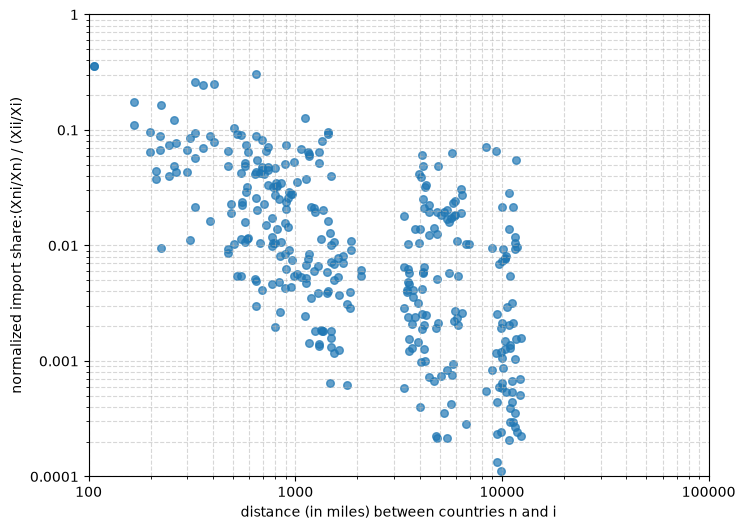

In [15]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(df_export['distance'], df_export['standardized_share'], s=30, alpha=0.7)

# 纵坐标对数刻度
ax.set_yscale('log')

# 指定要显示的刻度
ax.set_yticks([0.0001, 0.001, 0.01, 0.1, 1])

# 让刻度标签按原值显示，而不是科学计数法
ax.set_yticklabels(['0.0001', '0.001', '0.01', '0.1','1'])

# 可选：限制纵坐标范围
ax.set_ylim(0.0001, 1)

ax.set_xscale('log')   # 关键：纵坐标用对数刻度
ax.set_xticks([100, 1000, 10000, 100000])
ax.set_xticklabels(['100', '1000', '10000', '100000'])

# 可选：限制纵坐标范围
ax.set_xlim(100, 100000)

ax.set_xlabel('distance (in miles) between countries n and i')
ax.set_ylabel('normalized import share:(Xni/Xn) / (Xii/Xi)')
ax.grid(True, which='both', linestyle='--', alpha=0.5)

plt.show()

In [16]:
# 读取商品价格矩阵
df_ppp = pd.read_csv('pppdat1.prn', header=None)
price_matrix = df_ppp[0].values.reshape((18, 50))
df_price = pd.DataFrame(price_matrix)
# 以美国为基准，补充美国数据（全0）
df_price.loc[18] = [0] * 50
df_price

,0,1,2,3,4,5,6,7,8,9,...,40,41,42,43,44,45,46,47,48,49
0,0.161989,-0.315302,0.451650,0.646735,0.092289,0.438220,0.118827,0.622043,-0.077794,-0.188575,...,0.233926,0.189977,0.316423,0.205896,0.291221,0.057728,0.685799,0.499404,-0.139205,-0.198938
1,0.567858,0.040884,0.626906,0.778685,0.042085,0.450719,0.321531,0.893911,0.261107,0.291183,...,0.335591,0.446509,0.758016,0.715392,0.543827,0.273246,0.617229,-0.008043,0.406579,-0.300053
2,0.515134,-0.100861,0.407550,0.674117,-0.096256,0.739956,0.101230,0.480046,0.155166,-0.170393,...,0.632448,0.387904,0.984379,0.609703,0.318914,0.332606,0.675548,0.480502,0.089332,-0.154065
3,0.417219,0.248158,0.249496,0.192377,0.049494,0.510573,0.283041,0.526925,-0.086842,-0.141690,...,0.259480,0.246817,0.247488,0.148955,0.035508,0.289488,0.652059,0.038817,0.274597,0.242111
4,0.649159,-0.020223,0.627496,0.632754,0.277600,1.187865,0.743538,0.856317,0.612377,0.052988,...,0.631705,0.677872,0.829839,0.826322,0.368516,0.531188,0.787412,0.210857,0.223206,-0.397866
5,0.796529,0.152668,0.754082,0.923049,0.154586,1.151724,0.723222,0.711583,0.410148,0.164540,...,0.721533,0.756883,1.162892,0.704362,1.156191,0.587760,0.744923,0.291252,0.511048,-0.479867
6,0.578505,-0.000171,0.527799,0.751085,-0.024678,0.307837,0.208937,0.597614,0.287554,-0.006764,...,0.563758,0.532276,1.164243,0.922291,0.507918,0.511346,0.692803,0.435106,0.080044,0.211319
7,0.255417,-0.149133,0.291817,0.590581,-0.224614,0.615473,0.131839,0.490842,0.244835,0.021344,...,0.466312,0.437739,0.943057,0.781864,0.232736,0.320956,0.601001,0.377614,-0.108147,-0.098972
8,0.466734,0.221986,0.502458,0.980480,0.034479,0.490448,-0.220059,0.421088,-0.239623,-0.429879,...,0.216704,0.192337,0.944162,0.001593,0.229145,-0.020744,0.263728,0.233888,-0.272059,-0.588944
9,0.165575,-0.157801,0.453423,0.767830,-0.104945,0.423525,0.044708,0.955121,-0.075708,0.284689,...,0.508305,0.451925,1.039433,0.791250,0.364731,0.332014,0.591686,0.350445,0.292342,-0.195294


In [17]:
# 50 个价格列
price_cols = df_price.columns
df_price['country'] = df_country['country']
# 构造所有有序国家对：19 * 18
pairs = pd.DataFrame(
    list(permutations(df_price['country'].tolist(), 2)),
    columns=['import_country', 'export_country']
)
df_price = df_price.set_index('country', drop=True)

# 新建差价 df
df_price_diff = pairs.copy()

# 差值 = 进口国价格 - 出口国价格
for c in price_cols:
    v1 = df_price.loc[pairs['import_country'].tolist(), c].to_numpy()
    v2 = df_price.loc[pairs['export_country'].tolist(), c].to_numpy()
    df_price_diff[c] = v1 - v2

论文中： 
$$D_{ni} = \frac{\max2_j\{r_{ni}(j)\}}{\Sigma_{j=1}^{50}[r_{ni}(j)]/50}(13)$$
实际：
$$D_{ni} = \max2_j\{r_{ni}(j)\} - \Sigma_{j=1}^{50}[r_{ni}(j)]/50$$
其中：
$$r_{ni}(j)=\ln p_n(j)-\ln p_i(j)$$

In [18]:
# 新列：第二大值 - 均值
df_price_diff['Dni'] = df_price_diff[price_cols].apply(
    lambda row: row.nlargest(2).iloc[-1] - row.mean(), axis=1)
df_price_diff['expDni'] = np.exp(df_price_diff['Dni'])
df_price_diff['ln_standardized_share'] = np.log(df_export['standardized_share'].astype(float))

### Table II

In [19]:
# 获取所有出现过的国家 id
all_countries = sorted(set(df_price_diff['import_country']).union(set(df_price_diff['export_country'])))

rows = []

for cid in all_countries:
    row = {'country': cid}
    
    # ---------- 作为进口国 ----------
    sub_import = df_price_diff[df_price_diff['import_country'] == cid].copy()
    # 最大 value
    idx_max = sub_import['expDni'].idxmax()
    row['import_maximum'] = sub_import.loc[idx_max, 'export_country']
    row['import_maximum_value'] = np.round(sub_import.loc[idx_max, 'expDni'], 2)
    # 最小 value
    idx_min = sub_import['expDni'].idxmin()
    row['import_minimum'] = sub_import.loc[idx_min, 'export_country']
    row['import_minimum_value'] = np.round(sub_import.loc[idx_min, 'expDni'], 2)
    
    # ---------- 作为出口国 ----------
    sub_export = df_price_diff[df_price_diff['export_country'] == cid].copy()
    # 最大 value
    idx_max = sub_export['expDni'].idxmax()
    row['export_maximum'] = sub_export.loc[idx_max, 'import_country']
    row['export_maximum_value'] = np.round(sub_export.loc[idx_max, 'expDni'], 2)
    # 最小 value
    idx_min = sub_export['expDni'].idxmin()
    row['export_minimum'] = sub_export.loc[idx_min, 'import_country']
    row['export_minimum_value'] = np.round(sub_export.loc[idx_min, 'expDni'], 2)
    
    rows.append(row)

result_df = pd.DataFrame(rows)
result_df = result_df.set_index('country', drop=True)
result_df['import_maximum'] = result_df['import_maximum'] + '(' + result_df['import_maximum_value'].astype(str) + ')'
result_df['import_minimum'] = result_df['import_minimum'] + '(' + result_df['import_minimum_value'].astype(str) + ')'
result_df['export_maximum'] = result_df['export_maximum'] + '(' + result_df['export_maximum_value'].astype(str) + ')'
result_df['export_minimum'] = result_df['export_minimum'] + '(' + result_df['export_minimum_value'].astype(str) + ')'
result_df = result_df[['import_minimum', 'import_maximum', 'export_minimum', 'export_maximum']].copy()

make_multiindex_columns(df=result_df,
                        column_mapping={'Foreign Source': ['import_minimum', 'import_maximum'],
                                        'Foreign Destination': ['export_minimum', 'export_maximum']})


### Figure II

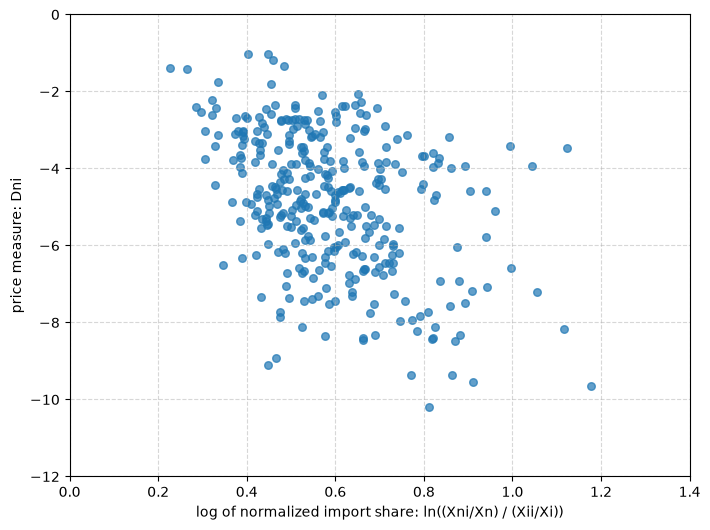

In [20]:
# 假设 df 是你的 DataFrame，取 A、B 两列
x = df_price_diff['Dni']
y = df_price_diff['ln_standardized_share']

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(x, y, s=30, alpha=0.7)

# 设置横纵坐标最小值和最大值
ax.set_xlim(0, 1.4)
ax.set_ylim(-12, 0)

# 设置刻度间隔
ax.xaxis.set_major_locator(MultipleLocator(0.2))  # 横轴间隔 10
ax.yaxis.set_major_locator(MultipleLocator(2))   # 纵轴间隔 5

# 可选：添加标签
ax.set_xlabel('log of normalized import share: ln((Xni/Xn) / (Xii/Xi))')
ax.set_ylabel('price measure: Dni')
ax.grid(True, which='both', linestyle='--', alpha=0.5)
plt.show()

0 截距假设下，$\theta = 8.28$

In [21]:
np.mean(y) / np.mean(x)

np.float64(-8.275827055105703)

In [22]:
slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
print(slope, intercept)
print(r_value, p_value, std_err)

-4.572015123998342 -2.1730013737664993
-0.40418040273733646 7.152136931411353e-15 0.561127809808072


# 回归

$$ \ln \frac{X'_{ni}}{X'_{nn}} = -\theta\ln d_{ni}+\frac{1}{\beta}\ln \frac{T_i}{T_n}-\theta\ln \frac{w_i}{w_n} (26) $$
$$ where: \ln X'_{ni} = \ln X_{ni}-\frac{1-\beta}{\beta}\ln \frac{X_i}{X_{ii}}$$
$$ S_i = \frac{1}{\beta}\ln T_i-\theta\ln w_i (27) $$
$$\ln \frac{X'_{ni}}{X'_{nn}} = -\theta\ln d_{ni}+S_i-S_n  (28) $$
$$\ln d_{ni} = d_k + b + l + e_h + m_n + \delta_{ni} (29) $$

$\beta$: the average labor share in gross manufacturing production in sample \
因变量需要由$\beta$计算出 \
作者实际直接令 $\beta=0.21221$，并没有求解步骤，使用样本数据可以计算出相近的值，但是不知道作者具体使用了哪个变量作为权重 \
数据中已有作者算好的因变量，直接使用

### 基准 OLS

In [23]:
file_path = Path("regression_data.csv")
df_reg1 = pd.read_csv(file_path)
# 生成 Source 和 Destination 虚拟变量
dummies1 = pd.get_dummies(df_reg1['export_country'], prefix='S', dtype=int)
dummies2 = pd.get_dummies(df_reg1['import_country'], prefix='M', dtype=int)

# 拼接回原 df
df_reg1 = pd.concat([df_reg1, dummies1, dummies2], axis=1)
df_reg1 = df_reg1[df_reg1['import_country'] != df_reg1['export_country']].copy()

for i in range(1, 20):
    df_reg1[f'S_{i}'] = df_reg1[f'S_{i}'] - df_reg1[f'M_{i}']

for i in range(1, 19):
    df_reg1[f'S_{i}'] = df_reg1[f'S_{i}'] - df_reg1['S_19']
for i in range(1, 19):
    df_reg1[f'M_{i}'] = df_reg1[f'M_{i}'] - df_reg1['M_19']   

X = df_reg1[['dist1', 'dist2', 'dist3', 'dist4', 'dist5', 'dist6', 'border', 'common_language', 
             'both_in_EU', 'both_in_EFTA'] + ['S_' + str(i) for i in range(1, 19)] + 
             ['M_' + str(i) for i in range(1, 19)]]
Y = df_reg1['trade_prime']
model = sm.OLS(Y, X).fit()
ols_resid = model.resid
# 输出完整结果
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            trade_prime   R-squared:                       0.976
Model:                            OLS   Adj. R-squared:                  0.972
Method:                 Least Squares   F-statistic:                     263.8
Date:                Sat, 31 Oct 2026   Prob (F-statistic):          7.52e-213
Time:                        13:51:54   Log-Likelihood:                -217.52
No. Observations:                 342   AIC:                             527.0
Df Residuals:                     296   BIC:                             703.4
Df Model:                          45                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
dist1              -3.1024      0.155    -

In [24]:
def regression_display(model, scale=False):
    # ============================================================
    # 1. 提取系数和正确的标准误
    # ============================================================
    df_model_value = pd.DataFrame(model.params).T
    params = model.params
    params.loc['S_19'] = -df_model_value[['S_' + str(i) for i in range(1, 19)]].sum(axis=1)[0]
    params.loc['M_19'] = -df_model_value[['M_' + str(i) for i in range(1, 19)]].sum(axis=1)[0]

    bse = model.bse
    test_S = model.t_test(' + '.join(['S_' + str(i) for i in range(1, 19)]) + ' = 0')
    test_M = model.t_test(' + '.join(['M_' + str(i) for i in range(1, 19)]) + ' = 0')
    bse.loc['S_19'] = test_S.sd[0][0]
    bse.loc['M_19'] = test_M.sd[0][0]
    if scale:
        bse_corrected = bse / np.sqrt(model.scale)
    else:
        bse_corrected = bse
    

    if not isinstance(bse_corrected, pd.Series):
        bse_corrected = pd.Series(bse_corrected, index=params.index)

    # ============================================================
    # 2. 变量分类
    # ============================================================
    var_names = list(params.index)
    export_dummies = [v for v in var_names if v.startswith('S_')]
    import_dummies = [v for v in var_names if v.startswith('M_')]
    other_vars     = [v for v in var_names if v not in export_dummies and v not in import_dummies]

    # ============================================================
    # 3. Panel A：其他变量
    # ============================================================
    other_rows = []
    for v in other_vars:
        other_rows.append({
            'Variable':    v,
            'Coefficient': f"{params[v]:.2f}",
            'Std. Error':  f"({bse_corrected[v]:.2f})",
        })

    other_df = pd.DataFrame(other_rows)
    print(other_df.to_string(index=False))
    print()

    # ============================================================
    # 4. Panel B：出口国 vs 进口国虚拟变量并排
    # ============================================================
    n_dummies = max(len(export_dummies), len(import_dummies))

    rows = []
    for i in range(n_dummies):
        row = []

        if i < len(export_dummies):
            v = export_dummies[i]
            row += [v,
                    f"{params[v]:.2f}",
                    f"({bse_corrected[v]:.2f})"]
        else:
            row += ['', '', '']

        if i < len(import_dummies):
            v = import_dummies[i]
            row += [v,
                    f"{params[v]:.2f}",
                    f"({bse_corrected[v]:.2f})"]
        else:
            row += ['', '', '']

        rows.append(row)

    cols = ['Export Var', 'Export Coef', 'Export SE',
            'Import Var', 'Import Coef', 'Import SE']
    dummy_df = pd.DataFrame(rows, columns=cols)
    print(dummy_df.to_string(index=False))

In [25]:
regression_display(model=model)

       Variable Coefficient Std. Error
          dist1       -3.10     (0.15)
          dist2       -3.67     (0.11)
          dist3       -4.03     (0.10)
          dist4       -4.22     (0.15)
          dist5       -6.06     (0.09)
          dist6       -6.56     (0.10)
         border        0.30     (0.14)
common_language        0.51     (0.15)
     both_in_EU        0.04     (0.12)
   both_in_EFTA        0.54     (0.18)

Export Var Export Coef Export SE Import Var Import Coef Import SE
       S_1        0.19    (0.15)        M_1        0.24    (0.26)
       S_2       -1.16    (0.13)        M_2       -1.68    (0.20)
       S_3       -3.34    (0.12)        M_3        1.12    (0.18)
       S_4        0.41    (0.14)        M_4        0.69    (0.24)
       S_5       -1.75    (0.12)        M_5       -0.51    (0.19)
       S_6       -0.52    (0.13)        M_6       -1.33    (0.21)
       S_7        1.28    (0.12)        M_7        0.22    (0.18)
       S_8        2.35    (0.12)        M_

### GLS

残差项 $\delta_{ni}$ 由两部分组成：
$$
\delta_{ni} = \delta_{ni}^2 + \delta_{ni}^1
$$ 
其中，$\delta_{ni}^2$ 代表一种双向效应，$\delta_{ni}^1$ 代表单向效应，有：
$$
\delta_{ni}^2 = \delta_{in}^2 
$$
$$
\delta_{ni}^1 \neq \delta_{in}^1
$$

$$
\begin{aligned}
E(\delta_{ab}\delta_{cd}) &= E(\delta_{ab}^1 \delta_{cd}^1)+ E(\delta_{ab}^1 \delta_{cd}^2)+E(\delta_{ab}^2 \delta_{cd}^1)+E(\delta_{ab}^2 \delta_{cd}^2) \\
                             &= E(\delta_{ab}^1 \delta_{cd}^1) +E(\delta_{ab}^2 \delta_{cd}^2) \\
                             &= \begin{cases}
                                \sigma_1^2 + \sigma_2^2, & a=c, b=d  \\
                                \sigma_2^2, & a=d, b=c \\
                                0, & otherwise
                                \end{cases}
\end{aligned}
$$



误差项的上述性质导致OLS估计有偏，使用GLS估计。设误差向量$\delta$的协方差矩阵为$\Omega$，则系数向量$\beta$在GLS的估计中为：
$$
\hat{\beta}^{*} = (X^{T}\Omega^{-1}X)^{-1}X^{T}\Omega^{-1}Y
$$
协方差矩阵
$$
Var(\hat{\beta}^{*}) = (X^{T}\Omega^{-1}X)^{-1}
$$

具体机制：
1. 对协方差矩阵$\Omega$进行分解(正定矩阵):
$$
\Omega = SS^{T}
$$
2. 对原始OLS模型两边同时称$S^{-1}$，令$Y'=S^{-1}Y, X'=S^{-1}X, \delta'=S^{-1}\delta$，则新误差项的协方差矩阵变为：
$$
\begin{aligned}
    Var(\delta') &= S^{-1}Var(\delta)(S^{-1})^{T} \\
                 &= S^{-1}(SS^{T})(S^{-1})^{T} \\
                 &= I
\end{aligned}
$$

In [26]:
df_resid = pd.DataFrame(np.outer(ols_resid.values, ols_resid.values))
df_resid_anti = pd.DataFrame(ols_resid)
df_resid_anti['import_country'] = df_reg1['import_country'].values
df_resid_anti['export_country'] = df_reg1['export_country'].values

row_of = {}
for idx, (imp, exp) in enumerate(zip(df_reg1['import_country'], df_reg1['export_country'])):
    row_of[(exp, imp)] = idx

countries = [i for i in range(1, 20)]
n = 342
# ============================================================
#    估计 E[σ2^2]（互惠方差）
#    对每个国家对 (i,j)，i<j，取其镜像残差乘积 u_{ij} * u_{ji}
# ============================================================
pairs_a2 = []
for i in countries:
    for j in countries:
        if i < j and (i, j) in row_of and (j, i) in row_of:
            u_ij = ols_resid.values[row_of[(i, j)]]   # 从 i 出口到 j 进口
            u_ji = ols_resid.values[row_of[(j, i)]]   # 从 j 出口到 i 进口
            pairs_a2.append(u_ij * u_ji)

E_a2 = np.mean(pairs_a2)          # 互惠部分方差
E_u2 = np.mean(ols_resid.values ** 2)            # 总方差 = E[σ1^2] + E[σ2^2]

print(f"E[σ2^2] (互惠方差) = {E_a2:.6f}")
print(f"E[u^2] (总方差)   = {E_u2:.6f}")
print(f"E[σ1^2] (单向方差) = {E_u2 - E_a2:.6f}")

# ============================================================
#   构造 Omega 矩阵 (n x n)
# ============================================================
Omega = np.zeros((n, n))

# 对角线：所有观测总方差
np.fill_diagonal(Omega, E_u2)

# 非对角线：同一国家对的镜像位置填 E[σ2^2]
for i in countries:
    for j in countries:
        if i < j and (i, j) in row_of and (j, i) in row_of:
            r1 = row_of[(i, j)]
            r2 = row_of[(j, i)]
            Omega[r1, r2] = E_a2
            Omega[r2, r1] = E_a2

gls_res = sm.GLS(Y, X, sigma=Omega).fit()
print(gls_res.summary())


# ============================================================
# 原始数据的 TSS 和 RSS（和论文可比）
# ============================================================
y_arr = np.asarray(Y, dtype=float).ravel()
X_arr = np.asarray(X, dtype=float)

# 用 GLS 系数预测原始 y
y_hat_gls = X_arr @ np.asarray(gls_res.params)
e_gls_raw = y_arr - y_hat_gls

TSS_raw = np.sum((y_arr - y_arr.mean())**2)
RSS_raw = np.sum(e_gls_raw**2)
R2_raw  = 1 - RSS_raw / TSS_raw

print(f"原始 TSS = {TSS_raw:.4f}")     
print(f"原始 RSS = {RSS_raw:.4f}")     
print(f"R²       = {R2_raw:.4f}")

E[σ2^2] (互惠方差) = 0.050650
E[u^2] (总方差)   = 0.208917
E[σ1^2] (单向方差) = 0.158267
                            GLS Regression Results                            
Dep. Variable:            trade_prime   R-squared:                       0.980
Model:                            GLS   Adj. R-squared:                  0.977
Method:                 Least Squares   F-statistic:                     319.4
Date:                Sat, 31 Oct 2026   Prob (F-statistic):          7.95e-225
Time:                        13:51:54   Log-Likelihood:                -212.34
No. Observations:                 342   AIC:                             516.7
Df Residuals:                     296   BIC:                             693.1
Df Model:                          45                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------

#### Table III

In [27]:
regression_display(model=gls_res, scale=True)

       Variable Coefficient Std. Error
          dist1       -3.10     (0.16)
          dist2       -3.66     (0.11)
          dist3       -4.03     (0.10)
          dist4       -4.22     (0.16)
          dist5       -6.06     (0.09)
          dist6       -6.56     (0.10)
         border        0.30     (0.14)
common_language        0.51     (0.15)
     both_in_EU        0.04     (0.13)
   both_in_EFTA        0.54     (0.19)

Export Var Export Coef Export SE Import Var Import Coef Import SE
       S_1        0.19    (0.15)        M_1        0.24    (0.27)
       S_2       -1.16    (0.12)        M_2       -1.68    (0.21)
       S_3       -3.34    (0.11)        M_3        1.12    (0.19)
       S_4        0.41    (0.14)        M_4        0.69    (0.25)
       S_5       -1.75    (0.12)        M_5       -0.51    (0.19)
       S_6       -0.52    (0.12)        M_6       -1.33    (0.22)
       S_7        1.28    (0.11)        M_7        0.22    (0.19)
       S_8        2.35    (0.12)        M_

In [28]:
df_info['Research Stock(U.S. = 1)'] = df_info['research_stock'] / df_info.loc[18]['research_stock']
df_info['Density(pop/area)(U.S. = 1)'] = df_info['density'] / df_info.loc[18]['density']
df_info['adjusted_labor_force'] = df_info['labor_force'] * np.exp(0.06 * df_info['educ']) / df_info.loc[18]['labor_force']
df_info['Labor force(HK adjusted)(U.S. = 1)'] = df_info['adjusted_labor_force'] / df_info.loc[18]['adjusted_labor_force']

#### Table IV

In [29]:
np.round(df_info[['Research Stock(U.S. = 1)', 'educ', 
         'Labor force(HK adjusted)(U.S. = 1)', 'Density(pop/area)(U.S. = 1)']].set_index(df_country['country']), 4)

,Research Stock(U.S. = 1),educ,Labor force(HK adjusted)(U.S. = 1),Density(pop/area)(U.S. = 1)
country,,,,
Australia,0.0087,8.72,0.0540,0.0829
Austria,0.0063,8.57,0.0241,3.4333
Belgium,0.0151,9.35,0.0287,12.0233
Canada,0.0299,9.98,0.0950,0.0994
Denmark,0.0051,6.91,0.0171,4.4710
Finland,0.0053,10.83,0.0193,0.5533
France,0.1108,9.54,0.1814,3.8787
Germany,0.1683,10.33,0.2249,9.4961
Greece,0.0005,8.40,0.0252,2.8678


### 用工资数据估计参数 $\theta$
$$S_i = \alpha_0+\alpha_{R}\ln R_i -\alpha_{H}\frac{1}{H_i} - \theta\ln w_i + \tau_i$$

In [30]:
df_reg2 = pd.DataFrame(gls_res.params[['S_' + str(i) for i in range(1, 19)]], columns=['source'])
df_reg2.loc['S_19', 'source'] = -df_reg2['source'].sum()
df_reg2['lnr&d'] = np.log(df_info['Research Stock(U.S. = 1)'].values)
df_reg2['educ'] = 1 / df_info['educ'].values
# 这里工资的计算，是先以美国为基准，调整原始工资，再由人力资本调整
# 作者原始数据给的是 np.log(df_info['nominal_wage'] / df_info.loc[18, 'nominal_wage'])
df_reg2['lnwage'] = np.log((df_info['nominal_wage'] / df_info.loc[18, 'nominal_wage'] * np.exp(-0.06 * df_info['educ'])).values)

#### Table V

In [31]:
X_2 = df_reg2[['lnr&d', 'educ', 'lnwage']]
Y_2 = df_reg2['source']
X_2 = sm.add_constant(X_2)
model2 = sm.OLS(Y_2, X_2).fit()
# 输出完整结果
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                 source   R-squared:                       0.770
Model:                            OLS   Adj. R-squared:                  0.724
Method:                 Least Squares   F-statistic:                     16.76
Date:                Sat, 31 Oct 2026   Prob (F-statistic):           4.70e-05
Time:                        13:51:54   Log-Likelihood:                -26.682
No. Observations:                  19   AIC:                             61.36
Df Residuals:                      15   BIC:                             65.14
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          3.7475      1.886      1.987      0.0

In [32]:
print(round(model2.centered_tss, 1))
print(round(model2.ssr, 1))

80.3
18.5


In [33]:
# 同理对劳动力先标准化，再按人力资本调整
# 注意：由于劳动力数据用于第一阶段回归，所以先标准化还是先调整，经对数处理后，只差一个常数项（美国的人力资源调整项），所以对最终结果无影响
df_reg2['labor'] = (np.log(df_info['labor_force'] / df_info.loc[18, 'labor_force']) + 0.06 * df_info['educ']).values
df_reg2['density'] = np.log(df_info['Density(pop/area)(U.S. = 1)']).values

In [34]:
# 解释变量矩阵：包含外生变量和内生变量
X_3 = sm.add_constant(df_reg2[['lnr&d', 'educ', 'lnwage']])

# 工具变量矩阵：包含外生变量和工具变量
Z = sm.add_constant(df_reg2[['lnr&d', 'educ', 'density', 'labor']])

res_sm = SM_IV2SLS(df_reg2["source"], X_3, Z).fit()
print(res_sm.summary())

                          IV2SLS Regression Results                           
Dep. Variable:                 source   R-squared:                       0.762
Model:                         IV2SLS   Adj. R-squared:                  0.714
Method:                     Two Stage   F-statistic:                     16.65
                        Least Squares   Prob (F-statistic):           4.87e-05
Date:                Sat, 31 Oct 2026                                         
Time:                        13:51:54                                         
No. Observations:                  19                                         
Df Residuals:                      15                                         
Df Model:                           3                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          3.8279      1.921      1.993      0.0

In [35]:
print(round(res_sm.centered_tss, 1))
print(round(res_sm.ssr, 1))

80.3
19.1


### 用价格数据估计参数 $\theta$
$$\ln \frac{X'_{ni}}{X'_{nn}}=-\theta\ln d_{ni}+S_i-S_n   (28)$$

In [36]:
df_reg3 = df_reg1[['S_' + str(i) for i in range(1, 19)] +['M_' + str(i) for i in range(1, 19)]]
df_reg3['Dni'] = df_price_diff['Dni'].values
df_reg3['trade_prime'] = df_reg1['trade_prime'].values
X_4 = df_reg3[['Dni'] + ['S_' + str(i) for i in range(1, 19)] +['M_' + str(i) for i in range(1, 19)]]
X_4 = sm.add_constant(X_4)
Y_4 = df_reg3['trade_prime']
model_4 = sm.OLS(Y_4, X_4).fit()
regression_display(model=model_4)

Variable Coefficient Std. Error
   const       -3.42     (0.29)
     Dni       -2.45     (0.49)

Export Var Export Coef Export SE Import Var Import Coef Import SE
       S_1       -1.41    (0.21)        M_1       -3.08    (0.31)
       S_2       -0.76    (0.21)        M_2       -0.94    (0.31)
       S_3       -3.08    (0.22)        M_3        1.72    (0.32)
       S_4       -0.72    (0.21)        M_4       -1.43    (0.30)
       S_5       -1.36    (0.21)        M_5        0.29    (0.30)
       S_6       -0.12    (0.21)        M_6       -0.54    (0.30)
       S_7        1.79    (0.21)        M_7        1.20    (0.30)
       S_8        2.84    (0.21)        M_8        2.04    (0.31)
       S_9       -2.49    (0.21)        M_9       -1.63    (0.30)
      S_10        1.96    (0.21)       M_10        0.49    (0.31)
      S_11        3.19    (0.22)       M_11       -0.46    (0.35)
      S_12       -1.78    (0.21)       M_12        1.83    (0.31)
      S_13       -2.14    (0.23)       M_13  

In [37]:
df_reg3['dist1'] = df_reg1['dist1'].values
df_reg3['dist2'] = df_reg1['dist2'].values
df_reg3['dist3'] = df_reg1['dist3'].values
df_reg3['dist4'] = df_reg1['dist4'].values
df_reg3['dist5'] = df_reg1['dist5'].values
df_reg3['dist6'] = df_reg1['dist6'].values
df_reg3['border'] = df_reg1['border'].values
df_reg3['common_language'] = df_reg1['common_language'].values
df_reg3['both_in_EU'] = df_reg1['both_in_EU'].values
df_reg3['both_in_EFTA'] = df_reg1['both_in_EFTA'].values

X_5 = sm.add_constant(df_reg3[['Dni'] + ['S_' + str(i) for i in range(1, 19)] +['M_' + str(i) for i in range(1, 19)]])

# 工具变量矩阵：包含外生变量和工具变量
Z_2 = sm.add_constant(df_reg3[['dist2', 'dist3', 'dist4', 'dist5', 'dist6', 'border', 
                               'common_language', 'both_in_EU', 'both_in_EFTA'] 
                               + ['S_' + str(i) for i in range(1, 19)] +['M_' + str(i) for i in range(1, 19)]])

res_sm_2 = SM_IV2SLS(df_reg3["trade_prime"], X_5, Z_2).fit()
regression_display(model=res_sm_2)

Variable Coefficient Std. Error
   const        2.69     (1.02)
     Dni      -12.86     (1.74)

Export Var Export Coef Export SE Import Var Import Coef Import SE
       S_1       -1.84    (0.33)        M_1       -4.38    (0.52)
       S_2       -1.31    (0.34)        M_2       -2.37    (0.53)
       S_3       -4.48    (0.40)        M_3       -0.76    (0.63)
       S_4       -0.90    (0.32)        M_4       -1.20    (0.47)
       S_5       -1.99    (0.34)        M_5       -0.89    (0.51)
       S_6       -0.12    (0.32)        M_6       -0.63    (0.47)
       S_7        1.47    (0.33)        M_7        0.46    (0.49)
       S_8        1.98    (0.35)        M_8        0.64    (0.52)
       S_9       -2.06    (0.33)        M_9       -0.46    (0.51)
      S_10        1.17    (0.35)       M_10       -0.87    (0.52)
      S_11        5.10    (0.45)       M_11        3.22    (0.77)
      S_12       -2.48    (0.34)       M_12        0.46    (0.52)
      S_13        0.25    (0.51)       M_13  

In [38]:
theta1 = 8.28    # 贸易份额估计
theta2 = 3.60    # 工资估计
theta3 = 12.86   # 价格估计
beta = 0.21221

### 技术估计

$$ 
S_i = \frac{1}{\beta}\ln T_i - \theta\ln w_i 
$$ 
$$ 
T_i = (e^{\hat{S_i}}w_i^{\theta})^\beta 
$$

#### Table VI

In [39]:
df_source = df_reg2[['source']]
# 注意这里工资的计算仍然是先以美国为基准对名义工资标准化，再经人力资本进行调整
df_source['wage'] = (df_info['nominal_wage'] / df_info.loc[18, 'nominal_wage'] * np.exp(-0.06 * df_info['educ'])).values
df_source['θ = 8.28'] = (np.exp(df_source['source']) * \
                         (df_source['wage'] ** theta1)) ** beta
df_source['θ = 8.28'] = df_source['θ = 8.28'] / df_source.loc['S_19', 'θ = 8.28']

df_source['θ = 3.60'] = (np.exp(df_source['source']) * \
                         (df_source['wage'] ** theta2)) ** beta
df_source['θ = 3.60'] = df_source['θ = 3.60'] / df_source.loc['S_19', 'θ = 3.60']

df_source['θ = 12.86'] = (np.exp(df_source['source']) * \
                         (df_source['wage'] ** theta3)) ** beta
df_source['θ = 12.86'] = df_source['θ = 12.86'] / df_source.loc['S_19', 'θ = 12.86']
np.round(df_source, 2).set_index(df_country['country']).rename(columns={'source': 'Estimated Source-country Competitiveness'})

,Estimated Source-country Competitiveness,wage,θ = 8.28,θ = 3.60,θ = 12.86
country,,,,,
Australia,0.19,0.36,0.27,0.36,0.20
Austria,-1.16,0.42,0.26,0.30,0.23
Belgium,-3.34,0.52,0.24,0.22,0.26
Canada,0.41,0.48,0.46,0.47,0.46
Denmark,-1.75,0.53,0.35,0.32,0.38
Finland,-0.52,0.53,0.45,0.41,0.50
France,1.28,0.52,0.64,0.60,0.69
Germany,2.35,0.52,0.81,0.75,0.87
Greece,-2.81,0.24,0.07,0.14,0.04


### 地理障碍估计

$$Effect = 100(e^{-\frac{\hat{d}}{\theta}}-1)$$

#### Table VII

In [40]:
df_dist = pd.DataFrame(gls_res.params[['dist1', 'dist2', 'dist3', 'dist4', 'dist5', 'dist6',
                               'border', 'common_language', 'both_in_EU', 'both_in_EFTA']], 
                                columns=['geography parameters'])
df_dist['θ = 8.28'] = 100 * (np.exp(-df_dist['geography parameters'] / theta1) - 1)
df_dist['θ = 3.60'] = 100 * (np.exp(-df_dist['geography parameters'] / theta2) - 1)
df_dist['θ = 12.86'] = 100 * (np.exp(-df_dist['geography parameters'] / theta3) - 1)
make_multiindex_columns(df=df_dist,
                        column_mapping={"Implied Barrier's % Effect on Cost": ['θ = 8.28', 'θ = 3.60', 'θ = 12.86']},
                        float_decimals=2,
                        float_as_str=True)

In [41]:
df_destination = pd.DataFrame(gls_res.params[['M_' + str(i) for i in range(1, 19)]],
                               columns=['destination parameters'])
df_destination.loc['M_19', 'destination parameters'] = -df_destination['destination parameters'].sum()
df_destination['θ = 8.28'] = 100 * (np.exp(-df_destination['destination parameters'] / theta1) - 1)
df_destination['θ = 3.60'] = 100 * (np.exp(-df_destination['destination parameters'] / theta2) - 1)
df_destination['θ = 12.86'] = 100 * (np.exp(-df_destination['destination parameters'] / theta3) - 1)
np.round(df_destination, 2).set_index(df_country['country'], drop=True)

,destination parameters,θ = 8.28,θ = 3.60,θ = 12.86
country,,,,
Australia,0.24,-2.81,-6.35,-1.82
Austria,-1.68,22.46,59.37,13.94
Belgium,1.12,-12.65,-26.74,-8.34
Canada,0.69,-7.99,-17.42,-5.22
Denmark,-0.51,6.33,15.15,4.03
Finland,-1.33,17.49,44.88,10.94
France,0.22,-2.61,-5.90,-1.69
Germany,1.00,-11.39,-24.27,-7.49
Greece,-2.36,32.93,92.45,20.11


# Counterfactual

### 估计参数 $\alpha$

$$X_{nn}+IMP_n=(1-\beta)(X_{nn}+EXP_n)+\alpha Y_n$$
论文中对$IMP$和$EMP$的定义分别为制造业的进口额和出口额 \
$\beta$: 劳动力份额 \
等式左边为制造业总吸收(国内销售 + 进口)，等式右边为制造业总需求(中间品需求 + 最终需求)

移项得：
$$
\begin{aligned}
\alpha &= \frac{\beta(X_{nn}+EXP_n)+IMP_n-EXP_n}{Y_n} \\
       &= \frac{w_nL_n+IMP_n-EXP_n}{Y_n} \\
\end{aligned}
$$



实际上，作者在计算 $\alpha$ 的过程中没有用到 $\beta$ 以及 $X_{nn}$，而是直接使用了制造业工资和劳动力数据 \
比较奇怪的是作者在这里用的数据是样本国之间的制造业进出口额，而非一国的总进出口额，Table I 曾展示 sample_import 占 total_import 的比重 \
导致的问题是由于以 $Y_n$为权重求平均，且 $\Sigma_n{(IMP_n-EXP_n)}=0$，考不考虑进出口得出的参数 $\alpha$ 是完全一致的

In [42]:
# 计算制造业工资
df_info['manufacture_income'] = df_info['nominal_wage'] * df_info['manufacture_labor']

# 对贸易数据按汇率进行调整
for i in range(1, 20):
    df_info['adjusted_trade_' + str(i)] = df_info['trade_' + str(i)] / df_info['exchange_rate'] * 1e6
trade_matrix = df_info[['adjusted_trade_' + str(i) for i in range(1, 20)]].copy()
diag = np.diag(trade_matrix.values)
# 行和：总进口（统计口径：样本内）
row_sum = trade_matrix.sum(axis=1).values    
# 列和：总出口（统计口径：样本内）       
col_sum = trade_matrix.sum(axis=0).values          

trade_matrix["import"] = row_sum - diag       # 行和 - 对角线
trade_matrix["export"] = col_sum - diag       # 列和 - 对角线

alpha = (df_info['manufacture_income'].values + trade_matrix["import"].values - trade_matrix["export"].values) / df_info['adj_gdp']
# 用 GDP 为权重对 alpha 向量求平均
alpha = np.average(alpha, weights=df_info['adj_gdp'])
alpha

np.float64(0.13481359059266584)

In [43]:
np.average(df_info['manufacture_income'] / df_info['adj_gdp'], weights=df_info['adj_gdp'])

np.float64(0.13481359059266584)

反事实核心等式：
$$p_n = \gamma \left[ \sum_{i=1}^N T_i (d_{ni} w_i^\beta p_i^{1-\beta})^{-\theta} \right]^{-1/\theta} (16)$$
$$\frac{X_{ni}}{X_n} = \pi_{ni} = T_i \left( \frac{\gamma d_{ni} w_i^\beta p_i^{1-\beta}}{p_n} \right)^{-\theta}(17)$$
$$w_i L_i = \sum_{n=1}^N \pi_{ni} \left[ (1-\beta) w_n L_n + \alpha \beta Y_n \right](20)$$
$$w_i L_i = \sum_{n=1}^N \pi_{ni} \left[ (1-\beta+\alpha\beta) w_n L_n + \alpha \beta Y_n^O \right](21)$$

令 $P_n=p_n^{-\theta}, D_{ni}=d_{ni}^{-\theta}$:
$$
\begin{aligned}
 \quad & P_n = \gamma^{-\theta} \sum_{i=1}^N T_i D_{ni} w_i^{-\beta\theta} P_i^{1-\beta} , \\[12pt]
 \quad & \frac{X_{ni}}{X_n} = \pi_{ni} = \gamma^{-\theta}\frac{ T_i D_{ni} w_i^{-\beta\theta} P_i^{1-\beta}}{P_n}
\end{aligned}
$$

地理障碍的计算取决于：
$$\ln d_{ni}=d_k+b+l+e_h+m_n+\delta_{ni}(29)$$

为了简单表示，将等式右侧各变量记为 $d_k$ \
在之前的回归中已经估计了 $e_k=-\theta d_k$，因此等式可以写成：
$$\ln d_{ni}=-\Sigma_k \frac{e_k}{\theta}$$

由 $D_{ni} = d_{ni}^{-\theta}$:
$$D_{ni}=e^{\Sigma_k e_k}$$
df_distance_matrix 已经计算好了 $\Sigma_k e_k$ ，因此只需要统一取 $e^{(·)}$，即得地理障碍矩阵 \
举例：进口国为澳大利亚(1)，出口国为奥地利(2)，地理障碍变量中取值为 1 的是 dist6(距离超 6000) 与 M_1(目的地为澳大利亚) 求和为 -6.56+0.24 = -6.32

In [44]:
df_distance_matrix

,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22
0,0.000000,-6.323086,-6.323086,-5.811442,-6.323086,-6.323086,-6.323086,-6.323086,-6.323086,-6.323086,-5.828454,-6.323086,-3.286113,-6.323086,-6.323086,-6.323086,-6.323086,-5.811442,-5.811442
1,-8.237020,0.000000,-5.342252,-7.742389,-5.342252,-5.174804,-5.342252,-3.969133,-5.711691,-5.046362,-7.742389,-5.342252,-8.237020,-5.174804,-5.711691,-5.711691,-5.174804,-5.711691,-7.742389
2,-5.439249,-2.544481,0.000000,-4.944618,-2.507629,-2.913920,-1.134510,-2.211739,-2.877068,-2.507629,-4.944618,-1.646153,-5.439249,-2.544481,-2.877068,-2.877068,-2.913920,-1.942044,-4.944618
3,-5.358506,-5.375518,-5.375518,0.000000,-5.375518,-5.375518,-5.375518,-5.375518,-5.375518,-5.375518,-5.870150,-5.375518,-5.358506,-5.375518,-5.375518,-5.375518,-5.375518,-4.863874,-2.167847
4,-7.067168,-4.172400,-4.135548,-6.572536,0.000000,-4.172400,-4.135548,-3.274072,-4.504987,-4.504987,-6.572536,-4.135548,-7.067168,-3.606815,-4.689193,-4.504987,-3.606815,-4.135548,-6.572536
5,-7.893964,-4.831748,-5.368635,-7.399333,-4.999196,0.000000,-5.368635,-4.999196,-5.552841,-5.368635,-7.399333,-5.368635,-7.893964,-4.462309,-5.552841,-5.552841,-3.600833,-5.368635,-7.399333
6,-6.340162,-3.445394,-2.035423,-5.845530,-3.408542,-3.814833,0.000000,-3.112651,-3.777981,-3.112651,-6.340162,-2.842957,-6.340162,-3.814833,-3.777981,-3.112651,-3.814833,-2.842957,-5.845530
7,-5.558314,-1.290427,-2.330803,-5.063682,-1.765218,-2.663546,-2.330803,0.000000,-2.996133,-2.330803,-5.063682,-1.765218,-5.558314,-2.663546,-2.996133,-2.996133,-2.663546,-2.626694,-5.063682
8,-8.916101,-6.390772,-6.353920,-8.421469,-6.353920,-6.574978,-6.353920,-6.353920,0.000000,-5.984480,-8.421469,-6.353920,-8.916101,-6.574978,-6.538125,-6.353920,-6.390772,-6.353920,-8.421469
9,-6.487561,-3.296903,-3.555941,-5.992930,-3.925380,-3.962232,-3.260050,-3.260050,-3.555941,0.000000,-6.487561,-3.925380,-6.487561,-3.962232,-3.925380,-3.925380,-3.962232,-3.925380,-5.992930


In [45]:
dni_matrix = np.exp(df_distance_matrix)

作者在这里令：
$$\gamma = \beta^{\beta}(1-\beta)^{(1-\beta)}$$
以下内容为个人想法，未验证：\
这里需要区分生产端的$\gamma_p$和需求端的$\gamma_d$，具体来说，作者在论文中的单位成本函数中省略了乘数$\gamma_p$(劳动力份额固定为$\beta$，考虑C-D生产函数生产一单位产品的成本最小化问题)，而在代码中补上了这个常数，原因是这个常数直接影响了劳动力和中间品的相对成本。 \
作者在论文中保留了需求端的 $\gamma_d$，但是在代码端省略了，或者说令 $\gamma_d=1$，理由是 $\gamma_d$ 会在计算过程中被吸收。

In [46]:
# 声明参数
alpha = alpha
beta = 0.21221
gamma = beta ** beta * (1-beta) ** (1-beta)
theta = 8.28

In [47]:
T = (np.exp(df_source['source'] - df_source.loc['S_19', 'source']) * 
     (df_info['Human-Capital Adj. Mfg. Wage (U.S.=1)'] ** theta).values) ** beta
T = T.values
T

array([0.26919343, 0.26067827, 0.2429388 , 0.46438066, 0.34790201,
       0.45432423, 0.63935002, 0.80554512, 0.06988056, 0.50435655,
       0.88744941, 0.30061915, 0.12295425, 0.42949536, 0.04091873,
       0.21496587, 0.51445955, 0.48574309, 1.        ])

In [48]:
w = df_info['adjusted_nominal_wage'].values
w

array([6.23195244, 7.20610436, 9.00156975, 8.27743125, 9.11878719,
       9.15176164, 8.93913494, 8.95732476, 4.15879936, 7.35232381,
       7.57401636, 8.84857762, 4.71911397, 9.79079641, 2.64005681,
       5.4100351 , 9.21049039, 7.56156736, 8.31995206])

### 计算 baseline

In [49]:
N = 19
w_init = w.copy()                         
Phi = np.ones(N)
L = np.asarray(df_info['adjusted_manufacture_labor'], dtype=float)
Y = np.asarray(df_info['adj_gdp'], dtype=float)
d = np.asarray(dni_matrix, dtype=float)

def solve_ek_model(L, Y, T, D, w_init, g, beta, theta, alpha):
    """
    参数:
        L: 劳动力
        Y: 总产出/GDP
        T: 技术水平
        D: 贸易成本矩阵
        w_init: 初始工资
        g: gamma 参数
        beta, theta, alpha: 模型结构参数
    """
    N = len(L)
    w = np.array(w_init, dtype=float)
    
    # 外层迭代
    for i in range(500):

        k = g * T * w**(-beta * theta)
        
        P_low = k**(1 / beta)
        P_high = np.full(N, np.sum(k)**(1 / beta))
        P_start = (P_low + P_high) / 2
        
        # (16) 式解 P
        def equations(P):
            P_safe = np.maximum(P, 1e-15) 
            return np.linalg.solve(D, P_safe) - k * (P_safe**(1 - beta))
        
        # 由于 P_start 是正数，通常能收敛到正数解。如果报错，可用 least_squares 加 bounds。
        if np.allclose(D, np.ones((N, N))):
            P = P_high
        else:
            sol = root(equations, P_start, tol=1e-12)
            if not sol.success:
                print(f"警告: 第 {i} 次外层迭代中，内层求解器未收敛: {sol.message}")
                # 尝试使用最小二乘法作为备选方案
                res_ls = least_squares(equations, P_start, bounds=(0, np.inf), xtol=1e-10)
                P = res_ls.x
            else:
                P = sol.x

        Pi = D * np.outer(1 / P, k * P**(1 - beta))

        # 用 (20) 式计算制造业收入 (世界市场对各国制造业产品的需求)
        Y_l = (1 - beta) * (Pi.T @ (w * L)) + alpha * beta * (Pi.T @ Y)

        # 引致的超额劳动需求
        excess_labor_ratio = (Y_l.flatten() / w - L) / L

        # 收敛性检验
        tolerance = np.sqrt(np.sum(excess_labor_ratio**2))

        if tolerance < 1e-12:
            print(f"收敛！外层迭代次数: {i}")
            # 精度符合要求，输出模型结果
            Xn = w * L * ((1 - beta) / beta) + alpha * Y
            Xni = Pi * Xn[:, np.newaxis]
            trade_volumn = np.sum(Xni) - np.sum(np.diag(Xni))
            W = Y * P ** (alpha / theta)

            return {
                "p": P**(-1 / theta),
                "w": w,
                "W": W,
                "Xni": Xni,
                "trade_volumn": trade_volumn
            }
        else:
            # 对劳动的超额需求会导致工资发生变化
            w = w * (1 + excess_labor_ratio * 0.3)  # 0.3 为弹性

    print("not convergent")
    return None

dict = solve_ek_model(L, Y, T, d, w_init, gamma ** -theta, beta, theta, alpha)

警告: 第 0 次外层迭代中，内层求解器未收敛: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
收敛！外层迭代次数: 79


In [50]:
np.mean((np.log(dict['w']) - np.log(w)) ** 2) ** 0.5

np.float64(0.05005590915601057)

In [51]:
def solve_mobile_model(T, d, w, Y, theta, beta, gamma, max_iter=10000):
    """
    参数
    ----------
    T : (N,) array
        各国技术参数 T_i。
    d : (N, N) array
        双边贸易壁垒 d[n, i] 表示从 i 到 n 的壁垒。
    w : (N,) array
        基准工资 w_i（已知，直接代入）。
    Y : (N,) array
        GDP
    theta : float
        比较优势参数。
    beta : float
        劳动成本份额。
    gamma : float
        常数项。
    tol : float
        收敛容差。
    max_iter : int
        最大迭代次数。
    
    返回
    -------
    p : (N,) array
        基准价格指数。
    """
    N = len(T)
    T = np.asarray(T, dtype=float)
    w = np.asarray(w, dtype=float)
    d = np.asarray(d, dtype=float)
    
    # 预计算矩阵 A，形状 (N, N)
    # A[n, i] = gamma^{-theta} * T_i * d[n,i]^{-theta} * w_i^{-beta*theta}
    A_tech = (gamma ** (-theta)) * T   # shape (N,)

    # 基准迭代矩阵
    A = A_tech[None, :] * d * (w[None, :] ** (-beta * theta))
    
    # 初始化 P = p^{-theta} = 1
    P = np.ones(N)
    
    for it in range(max_iter):
        P_new = A @ (P ** (1.0 - beta))
        # 相对误差：分母用 max(|x|, |x_new|)，避免除以零
        denom = np.maximum(np.abs(P_new), np.abs(P))
        diff = np.max(np.abs(P_new - P) / np.maximum(denom, 1e-300))
        P = P_new
        if diff < 1e-10:   # 相对误差 1e-10
            print(f"收敛，迭代次数 {it+1}")
            break
    else:
        print("警告：达到最大迭代次数仍未收敛，请检查参数或数据。")
    
    p = P ** (-1.0 / theta)

    Pi = A * (P ** (1 - beta))[np.newaxis, :] / P[:, np.newaxis]
    
    # 构建式(20)的线性方程组
    # w_i * L_i = sum_n Pi[n,i] * [(1-beta)*w_n*L_n + alpha*beta*Y_n]
    # 移项得: w_i * L_i - (1-beta) * sum_n Pi[n,i]*w_n*L_n = alpha*beta * sum_n Pi[n,i]*Y_n
    
    W = np.diag(w)
    
    # 左边的系数矩阵
    A_matrix = W - (1 - beta) * (Pi.T @ W)
    
    # 右边的常数项向量 (这里使用了 Pi.T @ Y)
    b_vector = alpha * beta * (Pi.T @ Y)
    
    # 求解线性方程组得到 L
    L = np.linalg.solve(A_matrix, b_vector)

    Xn = w * L * ((1 - beta) / beta) + alpha * Y
    
    # 计算双边贸易流矩阵 Xni[n, i] = Pi[n, i] * Xn[n]
    Xni = Pi * Xn[:, np.newaxis]
    
    # 计算世界总贸易量（总出口 = 所有国家的出口之和 = 总贸易流 - 国内贸易流）
    trade_volumn = np.sum(Xni) - np.sum(np.diag(Xni))

    W = Y * P ** (alpha / theta)
    
    return {
        "p": p,
        "w": w,
        "W": W,
        "Xni": Xni,
        "trade_volumn": trade_volumn,
        "L": L
    }

In [52]:
def solve_immobile_model(L, Y_o, T, d, w, gamma, beta, theta, alpha):
    """
    参数:
        L: 劳动力
        Y_o: 非制造业收入
        T: 技术水平
        d: 贸易成本矩阵
        w_init: 初始工资
        gamma, beta, theta, alpha: 模型结构参数
    """
    N = len(L)
    g = gamma ** -theta
    # 外层迭代
    for i in range(500):

        k = g * T * w**(-beta * theta)
        
        P_low = k**(1 / beta)
        P_high = np.full(N, np.sum(k)**(1 / beta))
        P_start = (P_low + P_high) / 2
        
        # (16) 式解 P 
        def equations(P):
            P_safe = np.maximum(P, 1e-15) 
            return np.linalg.solve(d, P_safe) - k * (P_safe**(1 - beta))
        is_diagonal = np.allclose(d - np.diag(np.diag(d)), 0)
        # 由于 P_start 是正数，通常能收敛到正数解。如果报错，可用 least_squares 加 bounds。
        if np.allclose(d, np.ones((N, N))):
            P = P_high
        elif is_diagonal:
            # 自给自足：D 是对角矩阵，直接解析解
            # 方程: D_nn * P_n = k_n * P_n^(1-beta)
            # 因为 D_nn = 1 (自给自足 d_nn=1, D_nn = d_nn^(-theta) = 1)
            # => P_n^beta = k_n => P_n = k_n^(1/beta)
            P = k**(1 / beta)
        else:
            sol = root(equations, P_start, tol=1e-12)
            if not sol.success:
                print(f"警告: 第 {i} 次外层迭代中，内层求解器未收敛: {sol.message}")
                # 尝试使用最小二乘法作为备选方案
                from scipy.optimize import least_squares
                res_ls = least_squares(equations, P_start, bounds=(0, np.inf), xtol=1e-10)
                P = res_ls.x
            else:
                P = sol.x

        if is_diagonal:
            # 自给自足下，没有国际贸易，贸易份额矩阵就是单位矩阵
            Pi = np.eye(N)
        else:
            Pi = d * np.outer(1 / P, k * P**(1 - beta))

        # 用 (21) 式计算制造业收入 (世界市场对各国制造业产品的需求)
        Y_l = (1 - beta + alpha * beta) * (Pi.T @ (w * L)) + alpha * beta * (Pi.T @ Y_o)

        # 引致的超额劳动需求
        excess_labor_ratio = (Y_l.flatten() / w - L) / L

        # 收敛性检验
        tolerance = np.sqrt(np.sum(excess_labor_ratio**2))

        if tolerance < 1e-12:
            print(f"收敛！外层迭代次数: {i}")
            # 精度符合要求，输出模型结果
            Xn = w * L * (alpha + (1 - beta) / beta) + alpha * Y_o
            Xni = Pi * Xn[:, np.newaxis]
            trade_volumn = np.sum(Xni) - np.sum(np.diag(Xni))
            W = (w * L + Y_o) * P ** (alpha / theta)

            return {
                "p": P**(-1 / theta),
                "w": w,
                "W": W,
                "Xni": Xni,
                "trade_volumn": trade_volumn
            }
        else:
            # 对劳动的超额需求会导致工资发生变化
            w = w * (1 + excess_labor_ratio * 0.3)  # 0.3 为弹性

    print("not convergent")
    return None


### 情境一：autarky

In [53]:
# 两国之间地理障碍趋于无穷
mask = np.eye(dni_matrix.shape[0], dni_matrix.shape[1], dtype=bool)
# True 的位置保留原值，False 的位置变为 0
df_diag = dni_matrix.where(mask, 0)
df_diag = np.asarray(df_diag, dtype=float)

In [54]:
# 劳动力可以自由流动
dict_mobile_1 = solve_mobile_model(T=T,
                                   d=df_diag,
                                   w=dict['w'],
                                   Y=Y,
                                   theta=theta,
                                   beta=beta,
                                   gamma=gamma)

收敛，迭代次数 98


In [55]:
# 劳动力不能自由流动
Y_o = (df_info['adj_gdp'] - dict['w'] * L).values
Y_o = np.asarray(Y_o, dtype=float)
dict_immobile_1 = solve_immobile_model(L=L, 
                                       Y_o=Y_o, 
                                       T=T, 
                                       d=df_diag, 
                                       w=dict['w'], 
                                       gamma=gamma, 
                                       beta=beta, 
                                       theta=theta, 
                                       alpha=alpha)

收敛！外层迭代次数: 461


#### Table IX

In [56]:
df_autarky = pd.DataFrame({
    'M_Welfare': np.log(dict_mobile_1['W'] / dict['W']) * 100, 
    'M_Mfg.Prices': np.log(dict_mobile_1['p'] / dict['p']) * 100,
    'M_Mfg.Labor': np.log(dict_mobile_1['L'] / L) * 100,
    'IM_Welfare': np.log(dict_immobile_1['W'] / dict['W']) * 100,
    'IM_Mfg.Prices': np.log(dict_immobile_1['p'] / dict['p']) * 100,
    'IM_Mfg.Wages': np.log(dict_immobile_1['w'] / dict['w']) * 100})
make_multiindex_columns(df=df_autarky,
                        column_mapping={'Mobile Labor': ['M_Welfare', 'M_Mfg.Prices', 'M_Mfg.Labor'], 
                                        'Immobile Labor': ['IM_Welfare', 'IM_Mfg.Prices', 'IM_Mfg.Wages']},
                        index=df_country['country'],
                        float_decimals=1,
                        float_as_str=True)

### 情景二：zero-gravity(mobile labor)

In [57]:
# 各国之间无地理障碍
zero_gravity = np.ones((19, 19), dtype=float)
dict_mobile_2 = solve_mobile_model(T=T,
                                   d=zero_gravity,
                                   w=dict['w'],
                                   Y=Y,
                                   theta=theta,
                                   beta=beta,
                                   gamma=gamma)

收敛，迭代次数 102


### 情境三：doubled trade(mobile labor)

$$ d_{ni}^{new}=0.69(d_{ni}^{old}-1)+1 $$
基准成本为 1(对角线元素为 1)，先减去 1，得到净运输摩擦

In [58]:
double_dni_matrix = ((dni_matrix ** (-1/theta) - 1) * 0.69 + 1) ** (-theta)
double_dni_matrix = np.asarray(double_dni_matrix, dtype=float)

In [59]:
dict_mobile_3 = solve_mobile_model(T=T,
                                   d=double_dni_matrix,
                                   w=dict['w'],
                                   Y=Y,
                                   theta=theta,
                                   beta=beta,
                                   gamma=gamma)

收敛，迭代次数 96


#### Table X

In [60]:
df_zero_gravity_and_doubled_trade = pd.DataFrame({
    'ZR_Welfare': np.log(dict_mobile_2['W'] / dict['W']) * 100, 
    'ZR_Mfg.Prices': np.log(dict_mobile_2['p'] / dict['p']) * 100,
    'ZR_Mfg.Labor': np.log(dict_mobile_2['L'] / L) * 100,
    'DT_Welfare': np.log(dict_mobile_3['W'] / dict['W']) * 100,
    'DT_Mfg.Prices': np.log(dict_mobile_3['p'] / dict['p']) * 100,
    'DT_Mfg.Labor': np.log(dict_mobile_3['L'] / L) * 100})
make_multiindex_columns(df=df_zero_gravity_and_doubled_trade,
                        column_mapping={'Mobile Labor': ['ZR_Welfare', 'ZR_Mfg.Prices', 'ZR_Mfg.Labor'], 
                                        'Immobile Labor': ['DT_Welfare', 'DT_Mfg.Prices', 'DT_Mfg.Labor']},
                        index=df_country['country'],
                        float_decimals=1,
                        float_as_str=True)

In [61]:
index = np.linspace(4, -4, 401)
x_list = [2 ** i for i in index]

In [62]:
total_labor = Y / dict['w']
labor_list = []
for x in x_list:
    d_plot = ((dni_matrix ** (-1/theta) - 1) * x + 1) ** (-theta)
    d_plot = np.asarray(d_plot, dtype=float)
    dict_mobile_plot = solve_mobile_model(T=T,
                                          d=d_plot,
                                          w=dict['w'],
                                          Y=Y,
                                          theta=theta,
                                          beta=beta,
                                          gamma=gamma)
    L_plot = dict_mobile_plot['L']
    labor_list.append(L_plot)
labor_proportion = [labor / total_labor for labor in labor_list]


收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97
收敛，迭代次数 97

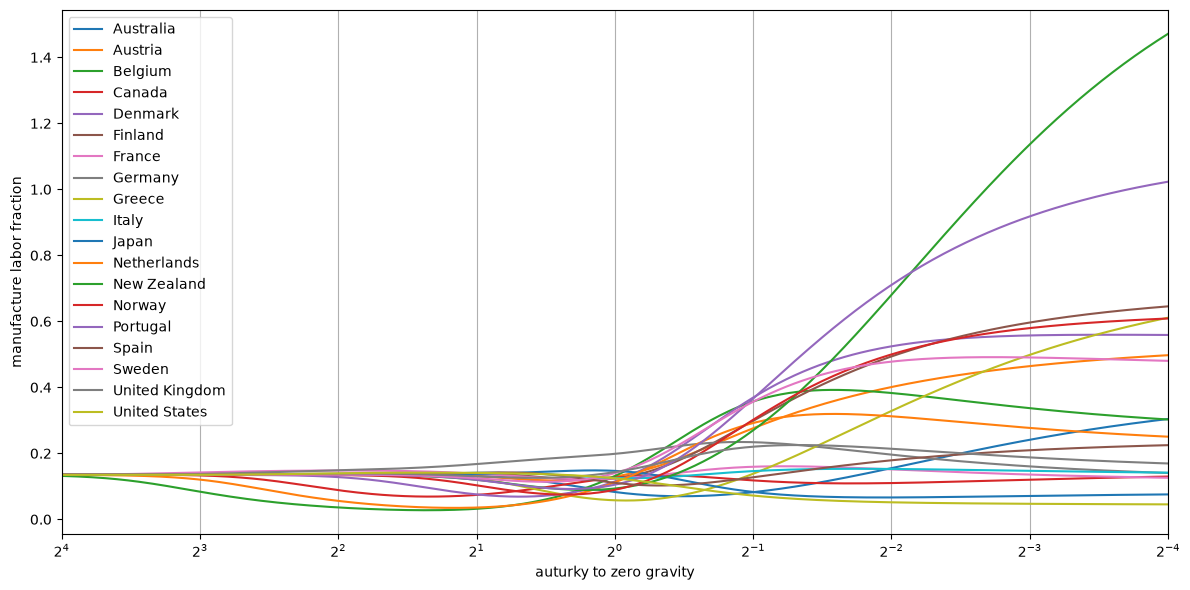

In [63]:
x = x_list                 # 2^-4, ..., 2^4
y = labor_proportion
y = np.array(y).T
M = y.shape[0]
labels = df_country['country'].values

fig, ax = plt.subplots(figsize=(12, 6))
lines = []
for j in range(M):
    line, = ax.plot(x, y[j], label=labels[j])
    lines.append(line)

# 关键：使用以 2 为底的对数轴，使 2^n 的刻度等距
ax.set_xscale('log', base=2)

# 左边最大 2^4，右边最小 2^-4
ax.set_xlim(2**4, 2**-4)

# 设置主刻度：2^-4, 2^-3, ..., 2^4
ticks = 2.0 ** np.arange(-4, 5)

ax.set_xlabel('auturky to zero gravity')
ax.set_ylabel('manufacture labor fraction')
ax.grid(True, which='major', axis='x')
leg = ax.legend()   # 默认就支持点击图例切换显示
lined = {}
for legline, origline in zip(leg.get_lines(), lines):
    legline.set_picker(True)
    legline.set_pickradius(5)
    lined[legline] = origline

def on_pick(event):
    legline = event.artist
    origline = lined[legline]
    vis = not origline.get_visible()
    origline.set_visible(vis)
    legline.set_alpha(1.0 if vis else 0.2)
    fig.canvas.draw()

fig.canvas.mpl_connect('pick_event', on_pick)
plt.tight_layout()
plt.show()

#### Figure III

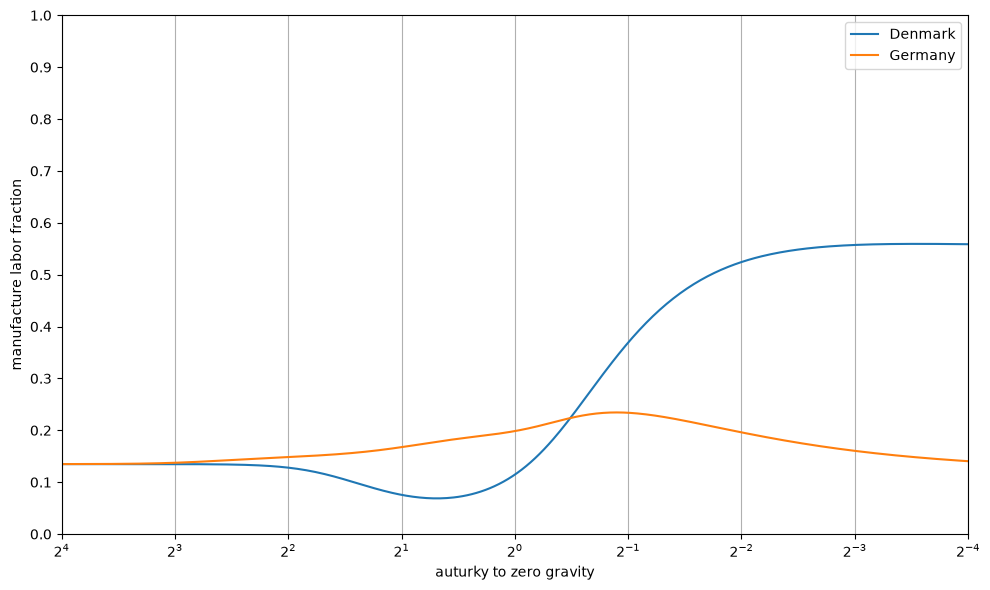

In [64]:
y = [[array[4], array[7]] for array in labor_proportion]
y = np.array(y).T

labels = ['Denmark', 'Germany']

fig, ax = plt.subplots(figsize=(10, 6))
lines = []
for j in range(2):
    line, = ax.plot(x, y[j], label=labels[j])
    lines.append(line)

# 关键：使用以 2 为底的对数轴，使 2^n 的刻度等距
ax.set_xscale('log', base=2)

# 左边最大 2^4，右边最小 2^-4
ax.set_xlim(2**4, 2**-4)

ax.set_yticks(np.arange(0, 1.1, 0.1))

# 设置主刻度：2^-4, 2^-3, ..., 2^4
ticks = 2.0 ** np.arange(-4, 5)

ax.set_xlabel('auturky to zero gravity')
ax.set_ylabel('manufacture labor fraction')
ax.grid(True, which='major', axis='x')
leg = ax.legend()   # 默认就支持点击图例切换显示
lined = {}
for legline, origline in zip(leg.get_lines(), lines):
    legline.set_picker(True)
    legline.set_pickradius(5)
    lined[legline] = origline

def on_pick(event):
    legline = event.artist
    origline = lined[legline]
    vis = not origline.get_visible()
    origline.set_visible(vis)
    legline.set_alpha(1.0 if vis else 0.2)
    fig.canvas.draw()

fig.canvas.mpl_connect('pick_event', on_pick)
plt.tight_layout()
plt.show()

### 情境四：提高美国的技术水平

In [65]:
T_1 = T.copy()
T_1[18] = T_1[18] * 1.2

In [66]:
# 劳动力可以自由流动
dict_mobile_4 = solve_mobile_model(T=T_1,
                                   d=d,
                                   w=dict['w'],
                                   Y=Y,
                                   theta=theta,
                                   beta=beta,
                                   gamma=gamma)

收敛，迭代次数 96


In [67]:
W_gain_US_mobile = (dict_mobile_4['W'] - dict['W']) / dict['W']
W_gain_US_stand_mobile = W_gain_US_mobile.copy()
W_gain_US_stand_mobile = W_gain_US_stand_mobile / W_gain_US_stand_mobile[18] * 100

In [68]:
# 劳动力不能自由流动
dict_immobile_2 = solve_immobile_model(L=L, 
                                       Y_o=Y_o, 
                                       T=T_1, 
                                       d=d, 
                                       w=dict['w'], 
                                       gamma=gamma, 
                                       beta=beta, 
                                       theta=theta, 
                                       alpha=alpha)

警告: 第 2 次外层迭代中，内层求解器未收敛: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
收敛！外层迭代次数: 85


In [69]:
W_gain_US_immobile = (dict_immobile_2['W'] - dict['W']) / dict['W']
W_gain_US_stand_immobile = W_gain_US_immobile.copy()
W_gain_US_stand_immobile = W_gain_US_stand_immobile / W_gain_US_stand_immobile[18] * 100

### 情境五：提高美国的技术水平

In [70]:
T_2 = T.copy()
T_2[7] = T_2[7] * 1.2

In [71]:
# 劳动力可以自由流动
dict_mobile_5 = solve_mobile_model(T=T_2,
                                   d=d,
                                   w=dict['w'],
                                   Y=Y,
                                   theta=theta,
                                   beta=beta,
                                   gamma=gamma)

收敛，迭代次数 95


In [72]:
W_gain_GE_mobile = (dict_mobile_5['W'] - dict['W']) / dict['W']
W_gain_GE_stand_mobile = W_gain_GE_mobile.copy()
W_gain_GE_stand_mobile = W_gain_GE_stand_mobile / W_gain_GE_stand_mobile[7] * 100

In [73]:
# 劳动力不能自由流动
dict_immobile_3 = solve_immobile_model(L=L, 
                                       Y_o=Y_o, 
                                       T=T_2, 
                                       d=d, 
                                       w=dict['w'], 
                                       gamma=gamma, 
                                       beta=beta, 
                                       theta=theta, 
                                       alpha=alpha)

收敛！外层迭代次数: 80


In [74]:
W_gain_GE_immobile = (dict_immobile_3['W'] - dict['W']) / dict['W']
W_gain_GE_stand_immobile = W_gain_GE_immobile.copy()
W_gain_GE_stand_immobile = W_gain_GE_stand_immobile / W_gain_GE_stand_immobile[7] * 100

#### Table XI

In [75]:
df_tech = pd.DataFrame({
    'US_M_Welfare': W_gain_US_stand_mobile, 
    'US_IM_Welfare': W_gain_US_stand_immobile,
    'GE_M_Welfare': W_gain_GE_stand_mobile,
    'GE_IM_Welfare': W_gain_GE_stand_immobile})
make_multiindex_columns(df=df_tech,
                        column_mapping={'Higher U.S. State of Technology': ['US_M_Welfare', 'US_IM_Welfare'], 
                                        'Higher German State of Technology': ['GE_M_Welfare', 'GE_IM_Welfare']},
                        index=df_country['country'],
                        float_decimals=1,
                        float_as_str=True)

### 情境六：移除关税

In [76]:
def solve_mobile_model_with_tariff(T, d, w, Y, theta, beta, gamma, tariff_matrix, tariff_base, max_iter=10000):
    """ 
    参数
    ----------
    T : (N,) array
        各国技术参数 T_i。
    d : (N, N) array
        双边贸易壁垒 d[n, i] 表示从 i 到 n 的壁垒。
    w : (N,) array
        基准工资 w_i（已知，直接代入）。
    Y : (N,) array
        GDP
    theta : float
        比较优势参数。
    beta : float
        劳动成本份额。
    gamma : float
        常数项。
    tariff_matrix : (N, N) array
        关税矩阵
    tariff_base : (N,) array
        基础关税
    tol : float
        收敛容差。
    max_iter : int
        最大迭代次数。
    
    返回
    -------
    p : (N,) array
        基准价格指数。
    """
    N = len(T)
    T = np.asarray(T, dtype=float)
    w = np.asarray(w, dtype=float)
    d = np.asarray(d, dtype=float)
    
    # 预计算矩阵 A，形状 (N, N)
    # A[n, i] = gamma^{-theta} * T_i * d[n,i]^{-theta} * w_i^{-beta*theta}
    A_tech = (gamma ** (-theta)) * T   # shape (N,)

    # 基准迭代矩阵
    A = A_tech[None, :] * d * (w[None, :] ** (-beta * theta))
    
    # 初始化 P = p^{-theta} = 1
    P = np.ones(N)
    
    for it in range(max_iter):
        P_new = A @ (P ** (1.0 - beta))
        # 相对误差：分母用 max(|x|, |x_new|)，避免除以零
        denom = np.maximum(np.abs(P_new), np.abs(P))
        diff = np.max(np.abs(P_new - P) / np.maximum(denom, 1e-300))
        P = P_new
        if diff < 1e-10:   # 相对误差 1e-10
            print(f"收敛，迭代次数 {it+1}")
            break
    else:
        print("警告：达到最大迭代次数仍未收敛，请检查参数或数据。")
    
    p = P ** (-1.0 / theta)

    Pi = A * (P ** (1 - beta))[np.newaxis, :] / P[:, np.newaxis]
    
    # 构建式(20)的线性方程组
    # w_i * L_i = sum_n Pi[n,i] * [(1-beta)*w_n*L_n + alpha*beta*Y_n]
    # 移项得: w_i * L_i - (1-beta) * sum_n Pi[n,i]*w_n*L_n = alpha*beta * sum_n Pi[n,i]*Y_n
    W = np.diag(w)
    
    # 左边的系数矩阵
    A_matrix = W - (1 - beta) * (Pi.T @ W)
    tau_share = tariff_matrix / (1 + tariff_matrix)  # 关税比例
    
    # 简单的外层循环，只需要跑几次
    TR_new = tariff_base.copy()
    for _ in range(50): # 够用
        Y_tar = Y + TR_new - tariff_base
        
        # 解出当前的 L
        # 右边的常数项向量 (这里使用了 Pi.T @ Y)
        b_vector = alpha * beta * (Pi.T @ Y_tar)
        L = np.linalg.solve(A_matrix, b_vector)
        
        # 当前的总需求和双边贸易流
        Xn = w * L * ((1 - beta) / beta) + alpha * Y_tar
        Xni = Pi * Xn[:, np.newaxis]
        
        # 求新 TR
        TR_candidate = np.sum(tau_share * Xni, axis=1)
        
        if np.max(np.abs(TR_candidate - TR_new)) < 1e-8:
            print('收敛')
            break

        TR_new = TR_candidate
    
    # 计算世界总贸易量（总出口 = 所有国家的出口之和 = 总贸易流 - 国内贸易流）
    trade_volumn = np.sum(Xni) - np.sum(np.diag(Xni))

    W = Y_tar * P ** (alpha / theta)
    
    return {
        "p": p,
        "w": w,
        "W": W,
        "Xni": Xni,
        "trade_volumn": trade_volumn,
        "L": L,
        'TR': TR_candidate
    }

In [77]:
def solve_immobile_model_with_tariff(L, Y_o, T, d, w, gamma, beta, theta, alpha, tariff_matrix, tariff_base):
    """
    参数:
        L: 劳动力
        Y_o: 非制造业部门收入
        T: 技术水平
        D: 贸易成本矩阵
        w_init: 初始工资
        g: gamma 参数
        beta, theta, alpha: 模型结构参数
        tariff_matrix : 关税矩阵
        tariff_base : 基础关税
    """
    N = len(L)
    g = gamma ** -theta
    # 外层迭代
    for i in range(2000):
        # 迭代初值

        k = g * T * w ** (-beta * theta)
        
        P_low = k**(1 / beta)
        P_high = np.full(N, np.sum(k)**(1 / beta))
        P_start = (P_low + P_high) / 2
        
        # (16) 式解 P 
        def equations(P):
            P_safe = np.maximum(P, 1e-15) 
            return np.linalg.solve(d, P_safe) - k * (P_safe**(1 - beta))
        # 由于 P_start 是正数，通常能收敛到正数解。如果报错，可用 least_squares 加 bounds。
        if np.allclose(d, np.ones((N, N))):
            P = P_high
        else:
            sol = root(equations, P_start, tol=1e-12)
            if not sol.success:
                print(f"警告: 第 {i} 次外层迭代中，内层求解器未收敛: {sol.message}")
                # 尝试使用最小二乘法作为备选方案
                res_ls = least_squares(equations, P_start, bounds=(0, np.inf), xtol=1e-12)
                P = res_ls.x
            else:
                P = sol.x

        Pi = d * np.outer(1 / P, k * P**(1 - beta))
        # 用 (21) 式计算制造业收入 (世界市场对各国制造业产品的需求)
        c = 1 - beta + alpha * beta
        cons = alpha * beta
        A = np.eye(N) - c * Pi.T
        Xn = w * L * (alpha + (1 - beta) / beta) + alpha * (Y_o + tariff_base)
        Xni = Pi * Xn[:, np.newaxis]
        Y_l = np.linalg.solve(A, cons * (Pi.T @ (Y_o + tariff_base)))
        tariff_base = np.sum((tariff_matrix / (1 + tariff_matrix)) * Xni, axis=1)
        excess_labor_ratio = (Y_l.flatten() / w - L) / L
        w = w * (1 + excess_labor_ratio * 0.3)  # 0.3 为弹性

        # 收敛性检验
        tolerance = np.sqrt(np.sum(excess_labor_ratio**2))

        if tolerance < 1e-10:
            print(f"收敛！外层迭代次数: {i}")

            P_low = k**(1 / beta)
            P_high = np.full(N, np.sum(k)**(1 / beta))
            P_start = (P_low + P_high) / 2
            if np.allclose(d, np.ones((N, N))):
                P = P_high
            else:
                sol = root(equations, P_start, tol=1e-12)
                if not sol.success:
                    print(f"警告: 第 {i} 次外层迭代中，内层求解器未收敛: {sol.message}")
                    # 尝试使用最小二乘法作为备选方案
                    res_ls = least_squares(equations, P_start, bounds=(0, np.inf), xtol=1e-12)
                    P = res_ls.x
                else:
                    P = sol.x
            Pi = d * np.outer(1 / P, k * P**(1 - beta))
            c = 1 - beta + alpha * beta
            cons = alpha * beta
            A = np.eye(N) - c * Pi.T
            Xn = w * L * (alpha + (1 - beta) / beta) + alpha * (Y_o + tariff_base)
            Xni = Pi * Xn[:, np.newaxis]
            Y_l = np.linalg.solve(A, cons * (Pi.T @ (Y_o + tariff_base)))
            tariff_base = np.sum((tariff_matrix / (1 + tariff_matrix)) * Xni, axis=1)
            
            trade_volumn = np.sum(Xni) - np.sum(np.diag(Xni))
            W = (Y_l + Y_o + tariff_base) * P ** (alpha / theta)
            return {
                "p": P**(-1 / theta),
                "w": w,
                "W": W,
                "Xni": Xni,
                "trade_volumn": trade_volumn,
                'TR': tariff_base,
                'Y_l': Y_l
            }

    print("not convergent")
    return None

In [78]:
t_matrix = np.full((N, N), 0.05)
np.fill_diagonal(t_matrix, 0) # 国内无关税
d_without_tariff = (1 + t_matrix) ** (theta) * d
tariff_matrix = np.zeros((19, 19))
# 计算初始关税
TRn = np.sum((t_matrix / (1 + t_matrix)) * dict['Xni'], axis=1)

In [79]:
# 劳动力可以自由流动
dict_mobile_6 = solve_mobile_model_with_tariff(T=T,
                                               d=d_without_tariff,
                                               w=dict['w'],
                                               Y=Y,
                                               theta=theta,
                                               beta=beta,
                                               gamma=gamma,
                                               tariff_matrix=tariff_matrix,
                                               tariff_base=TRn)
np.round(pd.DataFrame({'Aggregate Welfare': (
    dict_mobile_6['W'] - dict['W']) / dict['W'] * 100}).set_index(df_country['country']), 2)

收敛，迭代次数 95
收敛


,Aggregate Welfare
country,
Australia,0.28
Austria,-0.01
Belgium,-0.90
Canada,-0.67
Denmark,-0.21
Finland,0.16
France,0.19
Germany,0.02
Greece,0.44


In [80]:
# 移除关税的反事实中，计算福利时不减去基础关税，反而与论文中的结果一致
np.round(pd.DataFrame({'Aggregate Welfare': (
    Y / dict_mobile_6['p'] ** alpha - dict['W']) / dict['W'] * 100}).set_index(df_country['country']), 2)

,Aggregate Welfare
country,
Australia,0.65
Austria,1.01
Belgium,1.31
Canada,0.99
Denmark,1.16
Finland,0.94
France,0.97
Germany,0.86
Greece,1.02


In [81]:
# 劳动力不能自由流动
Y_o2 = (Y - dict['w'] * L - TRn)
Y_o2 = np.asarray(Y_o2, dtype=float)
dict_immobile_4 = solve_immobile_model_with_tariff(L=L, 
                                                   Y_o=Y_o2, 
                                                   T=T, 
                                                   d=d_without_tariff, 
                                                   w=w, 
                                                   gamma=gamma, 
                                                   beta=beta, 
                                                   theta=theta, 
                                                   alpha=alpha,
                                                   tariff_matrix=tariff_matrix,
                                                   tariff_base=TRn)
np.round(pd.DataFrame({'Aggregate Welfare': (
   dict_immobile_4['W'] - dict['W']) / dict['W'] * 100}).set_index(df_country['country']), 2)

收敛！外层迭代次数: 57


,Aggregate Welfare
country,
Australia,0.23
Austria,0.19
Belgium,0.60
Canada,0.56
Denmark,0.33
Finland,0.14
France,0.12
Germany,-0.05
Greece,0.32


### 情境七：移除美国关税

In [82]:
t_matrix = np.zeros((N, N))
t_matrix[-1] = 0.05
np.fill_diagonal(t_matrix, 0) # 国内无关税
d_tariff = (1 + t_matrix) ** theta * d
tariff_matrix = np.full((N, N), 0.05)
np.fill_diagonal(tariff_matrix, 0)
tariff_matrix[-1, :] = 0

In [83]:
# 劳动力可以自由流动
dict_mobile_7 = solve_mobile_model_with_tariff(T=T,
                                               d=d_tariff,
                                               w=dict['w'],
                                               Y=Y,
                                               theta=theta,
                                               beta=beta,
                                               gamma=gamma,
                                               tariff_matrix=tariff_matrix,
                                               tariff_base=TRn)
np.round(pd.DataFrame({'Aggregate Welfare': (
   dict_mobile_7['W'] - dict['W']) / dict['W'] * 100}).set_index(df_country['country']), 3)

收敛，迭代次数 95
收敛


,Aggregate Welfare
country,
Australia,0.061
Austria,0.029
Belgium,0.060
Canada,0.527
Denmark,0.043
Finland,0.033
France,0.028
Germany,0.034
Greece,0.030


In [84]:
# 劳动力不能自由流动
dict_immobile_5 = solve_immobile_model_with_tariff(L=L, 
                                                   Y_o=Y_o2, 
                                                   T=T, 
                                                   d=d_tariff, 
                                                   w=w, 
                                                   gamma=gamma, 
                                                   beta=beta, 
                                                   theta=theta, 
                                                   alpha=alpha,
                                                   tariff_matrix=tariff_matrix,
                                                   tariff_base=TRn)
np.round(pd.DataFrame({'Aggregate Welfare': (
   dict_immobile_5['W'] - dict['W']) / dict['W'] * 100}).set_index(df_country['country']), 2)

警告: 第 2 次外层迭代中，内层求解器未收敛: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
收敛！外层迭代次数: 99


,Aggregate Welfare
country,
Australia,0.07
Austria,0.03
Belgium,0.07
Canada,1.12
Denmark,0.04
Finland,0.04
France,0.02
Germany,0.05
Greece,0.02


In [85]:
price_effect = - alpha * 100 * np.log(dict_immobile_5['p'] / dict['p'])
wage_effect = 100 * (dict_immobile_5['w'] - dict['w']) * L / Y
tariff_effect = 100 * (dict_immobile_5['TR'] - TRn) / Y
price_effect + wage_effect + tariff_effect

array([ 0.07024883,  0.02669389,  0.06749365,  1.12258484,  0.04493164,
        0.0365079 ,  0.02491367,  0.0511157 ,  0.01936196,  0.02686036,
        0.02717766,  0.05260096,  0.13136114,  0.03426682,  0.0494583 ,
        0.02022664,  0.05669793,  0.07513901, -0.11359001])

### 情境八：移除 EC 内关税

In [86]:
EC_list = list(set(df_reg1[df_reg1['both_in_EU'] == 1]['import_country']))
EC_index_list = [i-1 for i in EC_list]
t_matrix = np.zeros((N, N))
# 生成包含关税的 D 矩阵
ec_grid = np.ix_(EC_index_list, EC_index_list)
t_matrix[ec_grid] = 0.05
np.fill_diagonal(t_matrix, 0) # 国内无关税
d_tariff_exclude_EC = (1 + t_matrix) ** (theta) * d
tariff_matrix = np.full((N, N), 0.05)
tariff_matrix[ec_grid] = 0
np.fill_diagonal(tariff_matrix, 0)

In [87]:
# 劳动力可以自由流动
dict_mobile_8 = solve_mobile_model_with_tariff(T=T,
                                               d=d_tariff_exclude_EC,
                                               w=dict['w'],
                                               Y=Y,
                                               theta=theta,
                                               beta=beta,
                                               gamma=gamma,
                                               tariff_matrix=tariff_matrix,
                                               tariff_base=TRn)

收敛，迭代次数 95
收敛


In [88]:
# 劳动力不能自由流动
dict_immobile_6 = solve_immobile_model_with_tariff(L=L, 
                                                   Y_o=Y_o2, 
                                                   T=T, 
                                                   d=d_tariff_exclude_EC, 
                                                   w=dict['w'], 
                                                   gamma=gamma, 
                                                   beta=beta, 
                                                   theta=theta, 
                                                   alpha=alpha,
                                                   tariff_matrix=tariff_matrix,
                                                   tariff_base=TRn)

收敛！外层迭代次数: 67


In [89]:
price_effect = - alpha * 100 * np.log(dict_immobile_6['p'] / dict['p'])
wage_effect = 100 * (dict_immobile_6['w'] - dict['w']) * L / Y
tariff_effect = 100 * (dict_immobile_6['TR'] - TRn) / Y
price_effect + wage_effect + tariff_effect

array([ 0.11337964, -0.06629837,  0.53501237,  0.00605463,  0.23626249,
       -0.01483167,  0.08505759,  0.00550603,  0.15150122,  0.06339723,
       -0.01296253,  0.41295412,  0.08603736,  0.05263783,  0.13359751,
        0.06494084, -0.09519038,  0.06026068,  0.03109606])

In [90]:
import_matrix = dict['Xni'].copy()
np.fill_diagonal(import_matrix, 0)
import_matrix_from_EC = import_matrix[:, EC_index_list]
import_EC_base = import_matrix_from_EC.sum(axis=1)

In [91]:
# 劳动力可以自由流动下，各国从 EC 国进口量的变化
import_matrix_mobile = dict_mobile_8['Xni'].copy()
np.fill_diagonal(import_matrix_mobile, 0)
import_matrix_from_EC_mobile = import_matrix_mobile[:, EC_index_list]
import_EC_mobile = import_matrix_from_EC_mobile.sum(axis=1)

In [92]:
# 劳动力不能自由流动下，各国从 EC 国进口量的变化
import_matrix_immobile = dict_immobile_6['Xni'].copy()
np.fill_diagonal(import_matrix_immobile, 0)
import_matrix_from_EC_immobile = import_matrix_immobile[:, EC_index_list]
import_EC_immobile = import_matrix_from_EC_immobile.sum(axis=1)

In [93]:
df_country['country'][EC_index_list]

2            Belgium
4            Denmark
6             France
7            Germany
8             Greece
9              Italy
11       Netherlands
14          Portugal
15             Spain
17    United Kingdom
Name: country, dtype: str

#### Table XII

劳动力不可流动的情境下，剔除关税的国家福利水平变化普遍较论文结果偏高，但是贸易量变化是一致的，说明工资、价格、关税收入等变量的值应该是准确的。

In [94]:
df_remove_EC_tariff = pd.DataFrame({
    'M_Welfare': (dict_mobile_8['W'] - dict['W']) / dict['W'] * 100, 
    'IM_Welfare': (dict_immobile_6['W'] - dict['W']) / dict['W'] * 100,
    'M_Import': (import_EC_mobile - import_EC_base) / import_EC_base * 100,
    'IM_Import':(import_EC_immobile - import_EC_base) / import_EC_base * 100})
make_multiindex_columns(df=df_remove_EC_tariff,
                        column_mapping={'Aggregate Welfare': ['M_Welfare', 'IM_Welfare'], 
                                        'Imports from the EC': ['M_Import', 'IM_Import']},
                        index=df_country['country'],
                        float_decimals=2,
                        float_as_str=True)